# LLM SFT & Preference Alignment Analysis
### *Model Accuracies, Visualizations, and Leaderboard Tables Across 3 Annotation Tasks*

#### Table of Contents
1. [Setup and Settings](#1.-Setup-and-Settings)
2. [Main Paper Figure (Accuracy vs. Training Size)](#2.-Main-Paper-Figure-(Accuracy-vs.-Training-Size))
3. [Table 7: Configuration Leaderboard](#3.-Table-7:-Configuration-Leaderboard)
4. [Table 8: Model Performance Comparison (Gemma 3 vs. Llama 3.1)](#4.-Table-8:-Model-Performance-Comparison-(Gemma-3-vs.-Llama-3.1))
5. [Detailed Configuration Analysis (Task-by-Task, F1 & Accuracy)](#5.-Detailed-Configuration-Analysis-(Task-by-Task,-F1-&-Accuracy))
6. [Seed-level Confusion Matrices](#6.-Seed-level-Confusion-Matrices)

In [43]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns
import matplotlib.lines as mlines
from IPython.display import display, Markdown, HTML

# Configure high-quality Seaborn styling for academic figures
sns.set_theme(style="white")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9.5,
    'figure.titlesize': 14,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight'
})
%matplotlib inline

print("Libraries successfully imported and visual properties set!")

Libraries successfully imported and visual properties set!


In [44]:
import os
import shlex
import subprocess
import sys
from pathlib import Path

# Dynamically check if in Colab
IN_COLAB = 'google.colab' in sys.modules

# Auto-install scipy if missing (required for ROC curve stats)
try:
    import scipy
except ImportError:
    print("scipy package not found. Installing scipy via pip...")
    subprocess.run([sys.executable, "-m", "pip", "install", "scipy"], check=True)
    import scipy
    print("scipy successfully installed!")

GITHUB_REPO = 'HydnumRepandum/Beyond-SFT'
CONFIG_PATH = '.git' # Define CONFIG_PATH here

if IN_COLAB:
    REPO_DIR = Path('/content/Beyond-SFT')
    if not REPO_DIR.exists():
        token = None
        try:
            from google.colab import userdata
            token = userdata.get('GITHUB_TOKEN')
        except Exception:
            token = None
        if token:
            from urllib.parse import quote
            clone_url = f"https://x-access-token:{quote(token, safe='')}@github.com/{GITHUB_REPO}.git"
        else:
            clone_url = f"https://github.com/{GITHUB_REPO}.git"
        subprocess.run(['git', 'clone', clone_url, str(REPO_DIR)], check=True)
else:
    # Robust local resolution searching candidates and their subfolders
    REPO_DIR = None
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / CONFIG_PATH).exists():
            REPO_DIR = candidate
            break
    if REPO_DIR is None:
        # Try finding a parent that contains Results_data_figures
        for candidate in [Path.cwd(), *Path.cwd().parents]:
            if (candidate / 'Results_data_figures').exists():
                REPO_DIR = candidate
                break
            if candidate.name == 'Results_data_figures':
                REPO_DIR = candidate.parent
                break
    if REPO_DIR is None:
        raise RuntimeError('Could not locate the repository root from the current working directory.')

os.chdir(REPO_DIR)
WORKSPACE_DIR = str(REPO_DIR)
src_dir = REPO_DIR / 'src'
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

def resolve_path(workspace_dir, *parts):
    """Robust path resolver that checks for both original and renamed/nested subfolders."""
    path_1 = os.path.join(workspace_dir, *parts)
    if os.path.exists(path_1):
        return path_1
    if len(parts) > 1 and parts[0] == 'Results_data_figures':
        path_2 = os.path.join(workspace_dir, 'Results_data_figures', 'beyond_sft_alignment_light_result', *parts[1:])
        if os.path.exists(path_2):
            return path_2
    return path_1

print('repo:', REPO_DIR)
print('config:', REPO_DIR / CONFIG_PATH)
print('workspace:', WORKSPACE_DIR)

repo: /Users/ematheve/Desktop/DPO-main
config: /Users/ematheve/Desktop/DPO-main/.git
workspace: /Users/ematheve/Desktop/DPO-main


## 1. Comparaison with Alizadeh (Accuracy vs. Training Size)

In this section, we parse baseline configurations (ChatGPT 3.5 and Llama 3 8B) from our Excel data, alongside the primary SFT & alignment experimental runs (DPO Hard Neg, DPO Rand Wrong, and KTO All Wrong) for Llama 3.1 and Gemma 3. We also plot the Llama 3.1 8B Zero-Shot baseline as a horizontal benchmark line.

In [45]:
def load_alignment_baseline(script_dir, model_id, task_id, config_name):
    """Loads the unique baseline accuracy_mean * 100 for zero-shot line."""
    file_path = resolve_path(script_dir, 'Results_data_figures', model_id, task_id, 'unified_colab', 'single_adapter_multi_inference', task_id, 'tables', 'aggregated_summary.csv')

    if not os.path.exists(file_path):
        file_path = resolve_path(script_dir, 'Results_data_figures', model_id, task_id, 'unified_colab', 'independent_adapters', task_id, 'tables', 'aggregated_summary.csv')

    if not os.path.exists(file_path):
        return None

    try:
        df = pd.read_csv(file_path)
        sub = df[df['method'] == config_name]
        if sub.empty:
            return None
        return sub['accuracy_mean'].values[0] * 100
    except Exception as e:
        print(f"Error loading baseline {model_id} {task_id} {config_name}: {e}")
        return None

def load_alignment_data(script_dir, model_id, task_id, config_name):
    """Loads train_size and accuracy_mean from alignment aggregated summaries."""
    file_path = resolve_path(script_dir, 'Results_data_figures', model_id, task_id, 'unified_colab', 'single_adapter_multi_inference', task_id, 'tables', 'aggregated_summary.csv')

    if not os.path.exists(file_path):
        file_path = resolve_path(script_dir, 'Results_data_figures', model_id, task_id, 'unified_colab', 'independent_adapters', task_id, 'tables', 'aggregated_summary.csv')

    if not os.path.exists(file_path):
        return None

    try:
        df = pd.read_csv(file_path)
        df['full_config'] = (df['method'] + '_' + df['preference_strategy'] + '_' + df['data_allocation']).str.replace('_na', '')

        sub = df[df['full_config'] == config_name]
        if sub.empty:
            return None

        sub = sub.copy()
        # Convert train_size to numeric to safely handle non-numeric values like 'na'
        sub['train_size'] = pd.to_numeric(sub['train_size'], errors='coerce')
        sub = sub.dropna(subset=['train_size'])
        sub['train_size'] = sub['train_size'].astype(int)
        sub['accuracy_pct'] = sub['accuracy_mean'] * 100
        sub = sub.sort_values(by='train_size')

        return sub[['train_size', 'accuracy_pct']].values
    except Exception as e:
        print(f"Error loading {model_id} {task_id} {config_name}: {e}")
        return None

In [46]:
def plot_accuracy_figures_llama31(workspace_dir):
    excel_path = os.path.join(workspace_dir, 'Results_data_figures', 'Result value accuracy Alizadeh et al.xlsx')

    if not os.path.exists(excel_path):
        print(f"Error: Excel file not found at {excel_path}")
        return

    df_excel = pd.read_excel(excel_path, sheet_name='Feuil1')
    df_excel = df_excel.dropna(subset=['Dataset', 'Task', 'Group'])

    tasks = [
        {
            'dataset': 'Tweets (2020-2021)',
            'task': 'Policy Frames (Super Frames)',
            'internal_id': 'ds1_task6',
            'title': 'Task 1: Tweets (2020–2021)\nPolicy Frames'
        },
        {
            'dataset': 'News Articles (2020-2021)',
            'task': 'Problem/Solution',
            'internal_id': 'ds4_task2',
            'title': 'Task 2: News Articles (2020–2021)\nProblem/Solution'
        },
        {
            'dataset': 'Tweets (2017-2022)',
            'task': 'Policy Frames (Super Frames)',
            'internal_id': 'ds3_task6',
            'title': 'Task 3: Tweets (2017–2022)\nPolicy Frames'
        }
    ]

    # Llama 3.1 Curves only
    curves_to_plot = [
        # --- 1. Excel Baselines ---
        {
            'type': 'excel',
            'group': 'ChatGPT',
            'shot': 'Fine-Tuning',
            'label': 'ChatGPT 3.5 (Fine-Tuning)',
            'style': {'color': '#10A37F', 'linestyle': '-', 'marker': 's', 'markersize': 5, 'linewidth': 1.5}
        },
        {
            'type': 'excel_horizontal',
            'group': 'ChatGPT',
            'shot': 'Zero-Shot',
            'label': 'ChatGPT 3.5 (Zero-Shot)',
            'style': {'color': '#10A37F', 'linestyle': '--', 'linewidth': 1.2, 'alpha': 0.7}
        },
        {
            'type': 'excel',
            'group': 'Llama 3 8b',
            'shot': 'Fine-Tuning',
            'label': 'Llama 3 8B (Fine-Tuning)',
            'style': {'color': '#64748B', 'linestyle': '-', 'marker': 'o', 'markersize': 5, 'linewidth': 1.5}
        },
        {
            'type': 'excel_horizontal',
            'group': 'Llama 3 8b',
            'shot': 'Zero-Shot',
            'label': 'Llama 3 8B (Zero-Shot)',
            'style': {'color': '#64748B', 'linestyle': '--', 'linewidth': 1.2, 'alpha': 0.7}
        },

        # --- 2. Llama 3.1 Curves ---
        {
            'type': 'alignment_horizontal',
            'model_id': 'llama31',
            'config_name': 'pretrained_baseline',
            'label': 'Llama 3.1 8B (Zero-Shot)',
            'style': {'color': '#1E40AF', 'linestyle': '-.', 'linewidth': 1.4, 'alpha': 0.8}
        },
        {
            'type': 'alignment',
            'model_id': 'llama31',
            'config_name': 'sft_shared',
            'label': 'Llama 3.1 (SFT)',
            'style': {'color': '#2563EB', 'linestyle': '-', 'marker': 'p', 'markersize': 6, 'linewidth': 1.8}
        },
        {
            'type': 'alignment',
            'model_id': 'llama31',
            'config_name': 'sft_dpo_hard_negative_shared',
            'label': 'Llama 3.1 (SFT+DPO Hard Neg)',
            'style': {'color': '#1E3A8A', 'linestyle': '-', 'marker': '^', 'markersize': 6, 'linewidth': 2.0}
        },
        {
            'type': 'alignment',
            'model_id': 'llama31',
            'config_name': 'sft_dpo_random_wrong_shared',
            'label': 'Llama 3.1 (SFT+DPO Rand Wrong)',
            'style': {'color': '#60A5FA', 'linestyle': '--', 'marker': 'v', 'markersize': 6, 'linewidth': 1.8}
        },
        {
            'type': 'alignment',
            'model_id': 'llama31',
            'config_name': 'sft_kto_all_wrong_shared',
            'label': 'Llama 3.1 (SFT+KTO All Wrong)',
            'style': {'color': '#06B6D4', 'linestyle': ':', 'marker': '<', 'markersize': 6, 'linewidth': 1.8}
        }
    ]

    fig, axes = plt.subplots(1, 3, figsize=(15, 6.2), sharey=False)
    fig.suptitle("Llama 3.1 8B", fontsize=14, fontweight="bold", y=0.98)

    for idx, t_info in enumerate(tasks):
        ax = axes[idx]
        task_df = df_excel[(df_excel['Dataset'] == t_info['dataset']) & (df_excel['Task'] == t_info['task'])]

        # Plot each curve sequentially
        for curve in curves_to_plot:
            ctype = curve['type']
            style = curve['style']

            if ctype == 'excel':
                sub_df = task_df[(task_df['Group'] == curve['group']) & (task_df['Shot'] == curve['shot'])].sort_values(by='Rows')
                if not sub_df.empty:
                    ax.plot(sub_df['Rows'].values, sub_df['Accuracy'].values, **style)

            elif ctype == 'excel_horizontal':
                sub_df = task_df[(task_df['Group'] == curve['group']) & (task_df['Shot'] == curve['shot'])]
                if not sub_df.empty:
                    ax.axhline(y=sub_df['Accuracy'].values[0], **style)

            elif ctype == 'alignment_horizontal':
                val = load_alignment_baseline(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if val is not None:
                    ax.axhline(y=val, **style)

            elif ctype == 'alignment':
                data = load_alignment_data(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if data is not None and len(data) > 0:
                    ax.plot(data[:, 0], data[:, 1], **style)

        # Formatting subplot details
        ax.set_title(t_info['title'].replace('\\n', '\n'), fontsize=12.5, fontweight='bold', pad=15)
        ax.set_xlabel('Training Dataset Size (number of rows)', fontsize=10, labelpad=8)

        if idx == 0:
            ax.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold', labelpad=8)
        else:
            ax.set_ylabel('Accuracy (%)', fontsize=10, labelpad=8)

        ax.set_xscale('log')

        # Dynamically set ticks
        all_sizes = list(task_df[task_df['Shot'] == 'Fine-Tuning']['Rows'].unique())
        for curve in curves_to_plot:
            if curve['type'] == 'alignment':
                data = load_alignment_data(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if data is not None:
                    all_sizes.extend(list(data[:, 0]))
        unique_sizes = sorted(list(set(all_sizes)))

        ax.set_xticks(unique_sizes)
        ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
        ax.set_xlim(min(unique_sizes) * 0.8, max(unique_sizes) * 1.25)
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
        ax.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
        sns.despine(ax=ax, top=True, right=True)
        ax.set_ylim(20, 95)

    # Draw Legend
    legend_handles = []
    legend_labels = []
    for curve in curves_to_plot:
        style = curve['style']
        label = curve['label']

        if 'marker' in style:
            handle = mlines.Line2D([], [],
                                   color=style['color'],
                                   linestyle=style['linestyle'],
                                   marker=style['marker'],
                                   markersize=style['markersize'],
                                   linewidth=style['linewidth'],
                                   label=label)
        else:
            handle = mlines.Line2D([], [],
                                   color=style['color'],
                                   linestyle=style['linestyle'],
                                   linewidth=style['linewidth'],
                                   alpha=style.get('alpha', 1.0),
                                   label=label)
        legend_handles.append(handle)
        legend_labels.append(label)

    fig.legend(handles=legend_handles, labels=legend_labels,
               loc='lower center',
               bbox_to_anchor=(0.5, -0.20),
               ncol=5,
               frameon=True,
               facecolor='white',
               edgecolor='#E2E8F0',
               fontsize=10)

    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.subplots_adjust(bottom=0.05)
    plt.show()

def plot_accuracy_figures_gemma3(workspace_dir):
    excel_path = os.path.join(workspace_dir, 'Results_data_figures', 'Result value accuracy Alizadeh et al.xlsx')

    if not os.path.exists(excel_path):
        print(f"Error: Excel file not found at {excel_path}")
        return

    df_excel = pd.read_excel(excel_path, sheet_name='Feuil1')
    df_excel = df_excel.dropna(subset=['Dataset', 'Task', 'Group'])

    tasks = [
        {
            'dataset': 'Tweets (2020-2021)',
            'task': 'Policy Frames (Super Frames)',
            'internal_id': 'ds1_task6',
            'title': 'Task 1: Tweets (2020–2021)\nPolicy Frames'
        },
        {
            'dataset': 'News Articles (2020-2021)',
            'task': 'Problem/Solution',
            'internal_id': 'ds4_task2',
            'title': 'Task 2: News Articles (2020–2021)\nProblem/Solution'
        },
        {
            'dataset': 'Tweets (2017-2022)',
            'task': 'Policy Frames (Super Frames)',
            'internal_id': 'ds3_task6',
            'title': 'Task3: Tweets (2017–2022)\nPolicy Frames'
        }
    ]

    # Gemma 3 Curves only
    curves_to_plot = [
        # --- 1. Excel Baselines ---
        {
            'type': 'excel',
            'group': 'ChatGPT',
            'shot': 'Fine-Tuning',
            'label': 'ChatGPT 3.5 (Fine-Tuning)',
            'style': {'color': '#10A37F', 'linestyle': '-', 'marker': 's', 'markersize': 5, 'linewidth': 1.5}
        },
        {
            'type': 'excel_horizontal',
            'group': 'ChatGPT',
            'shot': 'Zero-Shot',
            'label': 'ChatGPT 3.5 (Zero-Shot)',
            'style': {'color': '#10A37F', 'linestyle': '--', 'linewidth': 1.2, 'alpha': 0.7}
        },
        {
            'type': 'excel',
            'group': 'Llama 3 8b',
            'shot': 'Fine-Tuning',
            'label': 'Llama 3 8B (Fine-Tuning)',
            'style': {'color': '#64748B', 'linestyle': '-', 'marker': 'o', 'markersize': 5, 'linewidth': 1.5}
        },
        {
            'type': 'excel_horizontal',
            'group': 'Llama 3 8b',
            'shot': 'Zero-Shot',
            'label': 'Llama 3 8B (Zero-Shot)',
            'style': {'color': '#64748B', 'linestyle': '--', 'linewidth': 1.2, 'alpha': 0.7}
        },

        # --- 2. Gemma 3 Curves ---
        {
            'type': 'alignment',
            'model_id': 'gemma3',
            'config_name': 'sft_shared',
            'label': 'Gemma 3 (SFT)',
            'style': {'color': '#A78BFA', 'linestyle': '-', 'marker': 'p', 'markersize': 6, 'linewidth': 1.8}
        },
        {
            'type': 'alignment',
            'model_id': 'gemma3',
            'config_name': 'sft_dpo_hard_negative_shared',
            'label': 'Gemma 3 (SFT+DPO Hard Neg)',
            'style': {'color': '#5B21B6', 'linestyle': '-', 'marker': 'D', 'markersize': 5.5, 'linewidth': 2.0}
        },
        {
            'type': 'alignment',
            'model_id': 'gemma3',
            'config_name': 'sft_dpo_random_wrong_shared',
            'label': 'Gemma 3 (SFT+DPO Rand Wrong)',
            'style': {'color': '#8B5CF6', 'linestyle': '--', 'marker': 'd', 'markersize': 5.5, 'linewidth': 1.8}
        },
        {
            'type': 'alignment',
            'model_id': 'gemma3',
            'config_name': 'sft_kto_all_wrong_shared',
            'label': 'Gemma 3 (SFT+KTO All Wrong)',
            'style': {'color': '#EC4899', 'linestyle': ':', 'marker': '*', 'markersize': 7.5, 'linewidth': 1.8}
        }
    ]

    fig, axes = plt.subplots(1, 3, figsize=(15, 6.2), sharey=False)
    fig.suptitle("Gemma 3 12B", fontsize=14, fontweight="bold", y=0.98)

    for idx, t_info in enumerate(tasks):
        ax = axes[idx]
        task_df = df_excel[(df_excel['Dataset'] == t_info['dataset']) & (df_excel['Task'] == t_info['task'])]

        # Plot each curve sequentially
        for curve in curves_to_plot:
            ctype = curve['type']
            style = curve['style']

            if ctype == 'excel':
                sub_df = task_df[(task_df['Group'] == curve['group']) & (task_df['Shot'] == curve['shot'])].sort_values(by='Rows')
                if not sub_df.empty:
                    ax.plot(sub_df['Rows'].values, sub_df['Accuracy'].values, **style)

            elif ctype == 'excel_horizontal':
                sub_df = task_df[(task_df['Group'] == curve['group']) & (task_df['Shot'] == curve['shot'])]
                if not sub_df.empty:
                    ax.axhline(y=sub_df['Accuracy'].values[0], **style)

            elif ctype == 'alignment_horizontal':
                val = load_alignment_baseline(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if val is not None:
                    ax.axhline(y=val, **style)

            elif ctype == 'alignment':
                data = load_alignment_data(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if data is not None and len(data) > 0:
                    ax.plot(data[:, 0], data[:, 1], **style)

        # Formatting subplot details
        ax.set_title(t_info['title'].replace('\\n', '\n'), fontsize=12.5, fontweight='bold', pad=15)
        ax.set_xlabel('Training Dataset Size (number of rows)', fontsize=10, labelpad=8)

        if idx == 0:
            ax.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold', labelpad=8)
        else:
            ax.set_ylabel('Accuracy (%)', fontsize=10, labelpad=8)

        ax.set_xscale('log')

        # Dynamically set ticks
        all_sizes = list(task_df[task_df['Shot'] == 'Fine-Tuning']['Rows'].unique())
        for curve in curves_to_plot:
            if curve['type'] == 'alignment':
                data = load_alignment_data(workspace_dir, curve['model_id'], t_info['internal_id'], curve['config_name'])
                if data is not None:
                    all_sizes.extend(list(data[:, 0]))
        unique_sizes = sorted(list(set(all_sizes)))

        ax.set_xticks(unique_sizes)
        ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
        ax.set_xlim(min(unique_sizes) * 0.8, max(unique_sizes) * 1.25)
        ax.yaxis.set_major_formatter(ticker.PercentFormatter(decimals=0))
        ax.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
        sns.despine(ax=ax, top=True, right=True)
        ax.set_ylim(20, 95)

    # Draw Legend
    legend_handles = []
    legend_labels = []
    for curve in curves_to_plot:
        style = curve['style']
        label = curve['label']

        if 'marker' in style:
            handle = mlines.Line2D([], [],
                                   color=style['color'],
                                   linestyle=style['linestyle'],
                                   marker=style['marker'],
                                   markersize=style['markersize'],
                                   linewidth=style['linewidth'],
                                   label=label)
        else:
            handle = mlines.Line2D([], [],
                                   color=style['color'],
                                   linestyle=style['linestyle'],
                                   linewidth=style['linewidth'],
                                   alpha=style.get('alpha', 1.0),
                                   label=label)
        legend_handles.append(handle)
        legend_labels.append(label)

    fig.legend(handles=legend_handles, labels=legend_labels,
               loc='lower center',
               bbox_to_anchor=(0.5, -0.20),
               ncol=4,
               frameon=True,
               facecolor='white',
               edgecolor='#E2E8F0',
               fontsize=10)

    plt.tight_layout(rect=[0, 0.05, 1, 0.95])
    plt.subplots_adjust(bottom=0.05)
    plt.show()

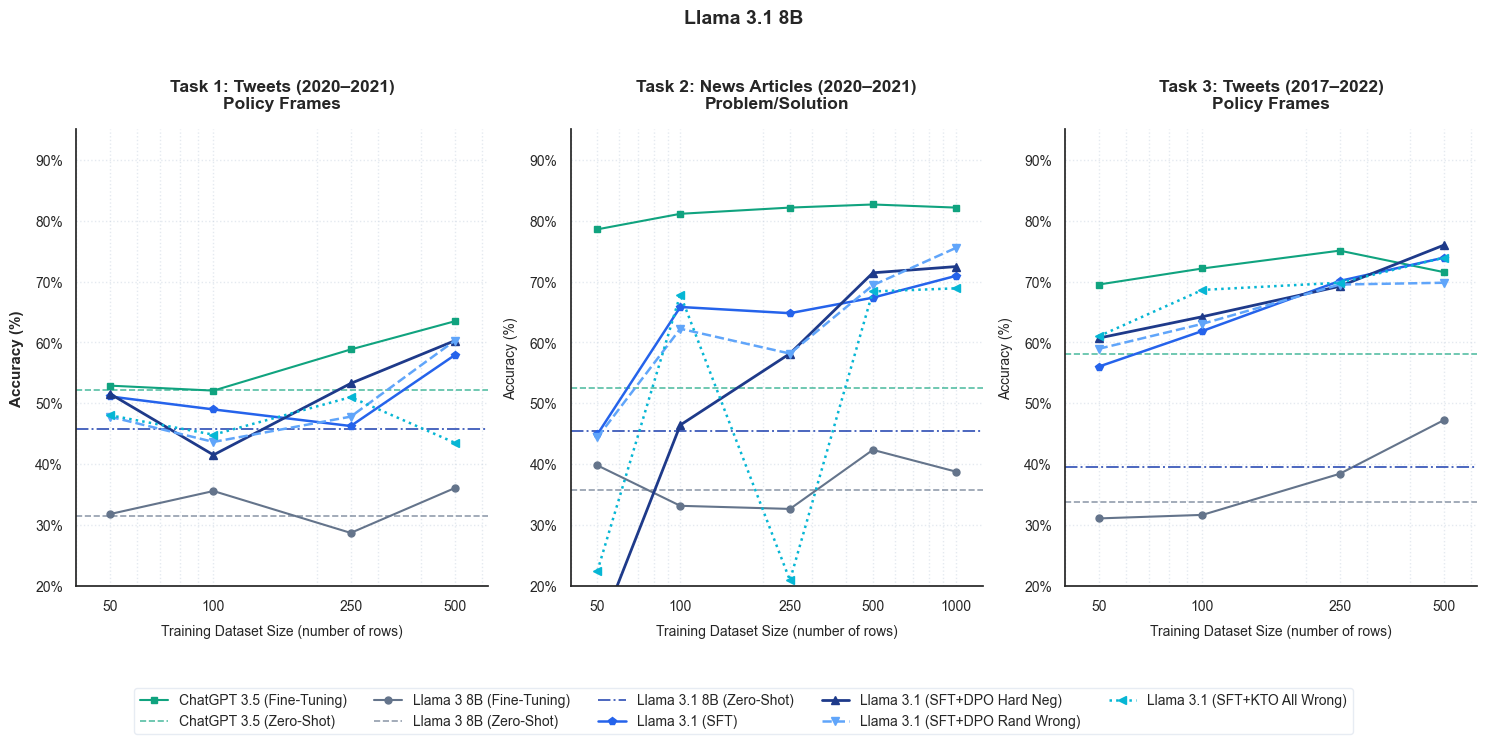

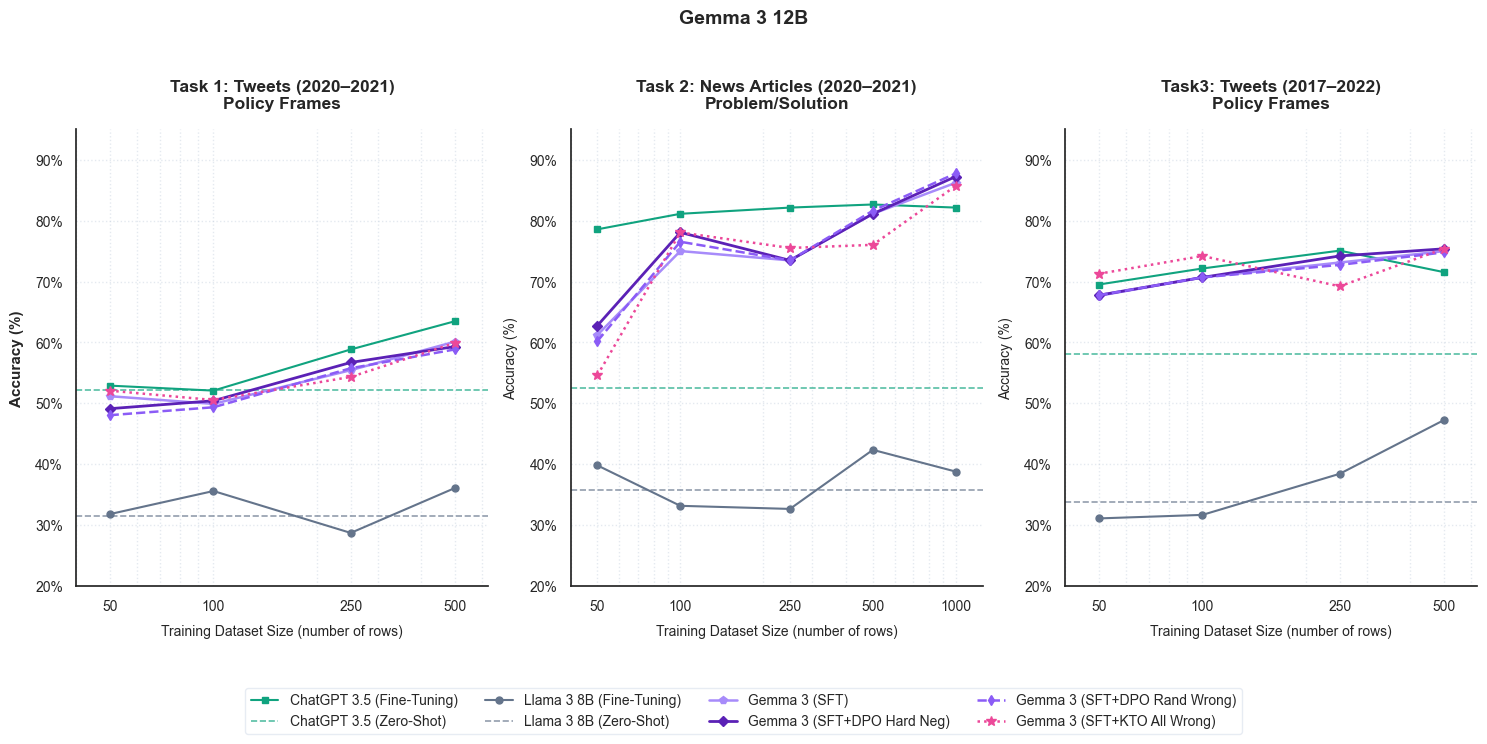

In [47]:
# Generate the plots inline
plot_accuracy_figures_llama31(WORKSPACE_DIR)
plot_accuracy_figures_gemma3(WORKSPACE_DIR)

## 2. Configuration Leaderboard

This table identifies the **best alignment configuration** for each task and training size based on macro F1-score and Mean Accuracy, and calculates the margin against the second-best configuration and standard SFT configuration.

In [48]:
def get_table7_data(script_dir):
    task_mapping = {'Task 1': 'ds1_task6', 'Task 2': 'ds4_task2', 'Task 3': 'ds3_task6'}
    models_map = {'Llama3.1': 'llama31', 'Gemma3': 'gemma3'}
    train_sizes = [50, 100, 250, 500, 1000]

    table_data = {}
    for task_friendly, task_internal in task_mapping.items():
        table_data[task_friendly] = {}
        for model_friendly, model_internal in models_map.items():
            table_data[task_friendly][model_friendly] = {}
            file_path = resolve_path(script_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'tables', 'aggregated_summary.csv')

            if not os.path.exists(file_path):
                for t_size in train_sizes:
                    table_data[task_friendly][model_friendly][t_size] = None
            else:
                df = pd.read_csv(file_path)
                # Exclude the sft25_dpo75 data allocation configuration
                df = df[df['data_allocation'] != 'sft25_dpo75']
                for t_size in train_sizes:
                    df_size = df[df['train_size'].astype(str) == str(t_size)]
                    if df_size.empty:
                        table_data[task_friendly][model_friendly][t_size] = None
                        continue
                    sft_df = df_size[df_size['method'] == 'sft']
                    sft_max_f1 = sft_df['macro_f1_mean'].max() if not sft_df.empty else np.nan

                    df_size = df_size[df_size['method'] != 'pretrained_baseline']
                    df_size = df_size.sort_values(by='macro_f1_mean', ascending=False)
                    if len(df_size) == 0:
                        table_data[task_friendly][model_friendly][t_size] = None
                        continue

                    best_row = df_size.iloc[0]
                    best_f1 = best_row['macro_f1_mean']
                    best_config_name = f"{best_row['method']}_{best_row['preference_strategy']}_{best_row['data_allocation']}".replace('_na', '')

                    second_best_f1 = np.nan
                    if len(df_size) > 1:
                        second_best_f1 = df_size.iloc[1]['macro_f1_mean']

                    gap_2nd = (best_f1 - second_best_f1) * 100 if not pd.isna(second_best_f1) else np.nan
                    gap_sft = (best_f1 - sft_max_f1) * 100 if not pd.isna(sft_max_f1) else np.nan

                    table_data[task_friendly][model_friendly][t_size] = {
                        'config': best_config_name, 'gap_2nd': gap_2nd, 'gap_sft': gap_sft
                    }
    return table_data, train_sizes

def display_table7(table_data, train_sizes):
    rows = []
    for task in ['Task 1', 'Task 2', 'Task 3']:
        for model in ['Llama3.1', 'Gemma3']:
            row_dict = {'Task': task, 'Model': model}
            for t_size in train_sizes:
                info = table_data[task][model][t_size]
                if info is None:
                    row_dict[str(t_size)] = "NA"
                else:
                    g2_str = f"+{info['gap_2nd']:.1f}%" if info['gap_2nd'] >= 0 else f"{info['gap_2nd']:.1f}%"
                    gs_str = f"+{info['gap_sft']:.1f}%" if info['gap_sft'] >= 0 else f"{info['gap_sft']:.1f}%"
                    row_dict[str(t_size)] = f"<b>{info['config']}</b><br><span style='font-size: 10px; color:#475569;'>({g2_str} 2nd, {gs_str} SFT)</span>"
            rows.append(row_dict)

    df_t7 = pd.DataFrame(rows)

    # Output HTML display for visual excellence
    html = df_t7.to_html(escape=False, index=False)
    # Custom table style injection
    styled_html = f"""
    <style>
        .styled-table {{ border-collapse: collapse; width: 100%; font-family: sans-serif; font-size: 11px; margin-top: 10px; }}
        .styled-table th, .styled-table td {{ border: 1px solid #CBD5E1; padding: 8px; text-align: center; vertical-align: middle; }}
        .styled-table th {{ background-color: #F1F5F9; font-weight: bold; }}
        .styled-table td b {{ font-family: monospace; font-size: 11px; color: #1E293B; background: #F8FAFC; padding: 2px 4px; border-radius: 4px; }}
    </style>
    """ + html.replace('class="dataframe"', 'class="styled-table"')
    display(HTML(styled_html))

In [49]:
t7_data, train_sizes = get_table7_data(WORKSPACE_DIR)
display_table7(t7_data, train_sizes)

Task,Model,50,100,250,500,1000
Task 1,Llama3.1,"sft_dpo_hard_negative_shared(+0.5% 2nd, +0.5% SFT)","sft_shared(+0.7% 2nd, +0.0% SFT)","sft_dpo_hard_negative_shared(+5.0% 2nd, +9.6% SFT)","sft_dpo_random_wrong_shared(+0.3% 2nd, +3.0% SFT)",NA
Task 1,Gemma3,"kto_all_wrong_shared(+1.2% 2nd, +6.0% SFT)","kto_all_wrong_shared(+0.7% 2nd, +8.2% SFT)","sft_dpo_hard_negative_shared(+1.2% 2nd, +2.3% SFT)","sft_shared(+0.6% 2nd, +0.0% SFT)",NA
Task 2,Llama3.1,"dpo_hard_negative_shared(+0.4% 2nd, +2.6% SFT)","sft_kto_all_wrong_shared(+1.7% 2nd, +1.7% SFT)","sft_shared(+4.0% 2nd, +0.0% SFT)","sft_dpo_random_wrong_shared(+0.2% 2nd, +5.4% SFT)","sft_dpo_random_wrong_shared(+0.9% 2nd, +3.8% SFT)"
Task 2,Gemma3,"sft_dpo_hard_negative_shared(+0.4% 2nd, +0.4% SFT)","sft_dpo_random_wrong_shared(+1.0% 2nd, +1.0% SFT)","sft_kto_all_wrong_shared(+1.4% 2nd, +2.1% SFT)","kto_all_wrong_shared(+0.8% 2nd, +1.8% SFT)","sft_dpo_random_wrong_shared(+0.7% 2nd, +1.0% SFT)"
Task 3,Llama3.1,"sft_dpo_hard_negative_shared(+0.9% 2nd, +4.9% SFT)","sft_dpo_hard_negative_shared(+2.0% 2nd, +2.0% SFT)","sft_shared(+6.5% 2nd, +0.0% SFT)","sft_shared(+0.2% 2nd, +0.0% SFT)",NA
Task 3,Gemma3,"sft_kto_all_wrong_shared(+2.1% 2nd, +2.1% SFT)","sft_kto_all_wrong_shared(+3.7% 2nd, +3.7% SFT)","sft_dpo_hard_negative_shared(+1.4% 2nd, +1.9% SFT)","sft_dpo_hard_negative_shared(+0.6% 2nd, +1.8% SFT)",NA


In [50]:
def get_table72_data(script_dir):
    task_mapping = {'Task 1': 'ds1_task6', 'Task 2': 'ds4_task2', 'Task 3': 'ds3_task6'}
    models_map = {'Llama3.1': 'llama31', 'Gemma3': 'gemma3'}
    train_sizes = [50, 100, 250, 500, 1000]

    table_data = {}
    for task_friendly, task_internal in task_mapping.items():
        table_data[task_friendly] = {}
        for model_friendly, model_internal in models_map.items():
            table_data[task_friendly][model_friendly] = {}
            file_path = resolve_path(script_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'tables', 'aggregated_summary.csv')

            if not os.path.exists(file_path):
                for t_size in train_sizes:
                    table_data[task_friendly][model_friendly][t_size] = None
            else:
                df = pd.read_csv(file_path)
                # Exclude the sft25_dpo75 data allocation configuration
                df = df[df['data_allocation'] != 'sft25_dpo75']
                for t_size in train_sizes:
                    df_size = df[df['train_size'].astype(str) == str(t_size)]
                    if df_size.empty:
                        table_data[task_friendly][model_friendly][t_size] = None
                        continue
                    sft_df = df_size[df_size['method'] == 'sft']
                    sft_max_f1 = sft_df['accuracy_mean'].max() if not sft_df.empty else np.nan

                    df_size = df_size[df_size['method'] != 'pretrained_baseline']
                    df_size = df_size.sort_values(by='accuracy_mean', ascending=False)
                    if len(df_size) == 0:
                        table_data[task_friendly][model_friendly][t_size] = None
                        continue

                    best_row = df_size.iloc[0]
                    best_f1 = best_row['accuracy_mean']
                    best_config_name = f"{best_row['method']}_{best_row['preference_strategy']}_{best_row['data_allocation']}".replace('_na', '')

                    second_best_f1 = np.nan
                    if len(df_size) > 1:
                        second_best_f1 = df_size.iloc[1]['accuracy_mean']

                    gap_2nd = (best_f1 - second_best_f1) * 100 if not pd.isna(second_best_f1) else np.nan
                    gap_sft = (best_f1 - sft_max_f1) * 100 if not pd.isna(sft_max_f1) else np.nan

                    table_data[task_friendly][model_friendly][t_size] = {
                        'config': best_config_name, 'gap_2nd': gap_2nd, 'gap_sft': gap_sft
                    }
    return table_data, train_sizes

def display_table72(table_data, train_sizes):
    rows = []
    for task in ['Task 1', 'Task 2', 'Task 3']:
        for model in ['Llama3.1', 'Gemma3']:
            row_dict = {'Task': task, 'Model': model}
            for t_size in train_sizes:
                info = table_data[task][model][t_size]
                if info is None:
                    row_dict[str(t_size)] = "NA"
                else:
                    g2_str = f"+{info['gap_2nd']:.1f}%" if info['gap_2nd'] >= 0 else f"{info['gap_2nd']:.1f}%"
                    gs_str = f"+{info['gap_sft']:.1f}%" if info['gap_sft'] >= 0 else f"{info['gap_sft']:.1f}%"
                    row_dict[str(t_size)] = f"<b>{info['config']}</b><br><span style='font-size: 10px; color:#475569;'>({g2_str} 2nd, {gs_str} SFT)</span>"
            rows.append(row_dict)

    df_t72 = pd.DataFrame(rows)

    # Output HTML display for visual excellence
    html = df_t72.to_html(escape=False, index=False)
    # Custom table style injection
    styled_html = f"""
    <style>
        .styled-table {{ border-collapse: collapse; width: 100%; font-family: sans-serif; font-size: 11px; margin-top: 10px; }}
        .styled-table th, .styled-table td {{ border: 1px solid #CBD5E1; padding: 8px; text-align: center; vertical-align: middle; }}
        .styled-table th {{ background-color: #F1F5F9; font-weight: bold; }}
        .styled-table td b {{ font-family: monospace; font-size: 11px; color: #1E293B; background: #F8FAFC; padding: 2px 4px; border-radius: 4px; }}
    </style>
    """ + html.replace('class="dataframe"', 'class="styled-table"')
    display(HTML(styled_html))

In [51]:
t72_data, train_sizes = get_table72_data(WORKSPACE_DIR)
display_table72(t72_data, train_sizes)

Task,Model,50,100,250,500,1000
Task 1,Llama3.1,"sft_dpo_hard_negative_shared(+0.5% 2nd, +0.5% SFT)","kto_all_wrong_shared(+0.9% 2nd, +0.9% SFT)","sft_dpo_hard_negative_shared(+2.3% 2nd, +7.0% SFT)","sft_dpo_hard_negative_shared(+0.0% 2nd, +2.4% SFT)",NA
Task 1,Gemma3,"kto_all_wrong_shared(+1.1% 2nd, +6.1% SFT)","kto_all_wrong_shared(+1.2% 2nd, +7.9% SFT)","kto_all_wrong_shared(+0.1% 2nd, +1.4% SFT)","sft_shared(+0.2% 2nd, +0.0% SFT)",NA
Task 2,Llama3.1,"dpo_hard_negative_shared(+0.5% 2nd, +1.0% SFT)","sft_kto_all_wrong_shared(+2.0% 2nd, +2.0% SFT)","sft_shared(+6.6% 2nd, +0.0% SFT)","sft_dpo_hard_negative_shared(+2.0% 2nd, +4.1% SFT)","sft_dpo_random_wrong_shared(+3.1% 2nd, +4.6% SFT)"
Task 2,Gemma3,"sft_dpo_hard_negative_shared(+1.5% 2nd, +1.5% SFT)","sft_dpo_hard_negative_shared(+0.0% 2nd, +3.1% SFT)","sft_kto_all_wrong_shared(+2.0% 2nd, +2.0% SFT)","kto_all_wrong_shared(+0.0% 2nd, +0.5% SFT)","sft_dpo_random_wrong_shared(+0.5% 2nd, +1.5% SFT)"
Task 3,Llama3.1,"sft_kto_all_wrong_shared(+0.3% 2nd, +5.0% SFT)","sft_kto_all_wrong_shared(+4.4% 2nd, +6.7% SFT)","sft_shared(+0.3% 2nd, +0.0% SFT)","sft_dpo_hard_negative_shared(+2.1% 2nd, +2.1% SFT)",NA
Task 3,Gemma3,"sft_kto_all_wrong_shared(+3.5% 2nd, +3.6% SFT)","sft_kto_all_wrong_shared(+3.5% 2nd, +3.5% SFT)","sft_dpo_hard_negative_shared(+1.1% 2nd, +1.1% SFT)","sft_dpo_hard_negative_shared(+0.0% 2nd, +0.4% SFT)",NA


In [53]:
import os
import numpy as np
import pandas as pd
from IPython.display import display, HTML

script_dir = WORKSPACE_DIR
def format_config_name(row):
    """
    Creates clean configuration names such as:
    sft
    dpo_best_sft50_dpo50
    kto_shared_sft50_kto50
    """
    parts = [str(row["method"])]

    for col in ["preference_strategy", "data_allocation"]:
        value = row.get(col, np.nan)

        if pd.isna(value):
            continue

        value = str(value)

        if value.lower() not in ["na", "nan", "none", ""]:
            parts.append(value)

    return "_".join(parts)


def get_best_metric_table_data(script_dir):
    task_mapping = {
        "Task 1": "ds1_task6",
        "Task 2": "ds4_task2",
        "Task 3": "ds3_task6"
    }

    models_map = {
        "Llama3.1": "llama31",
        "Gemma3": "gemma3"
    }

    train_sizes = [50, 100, 250, 500, 1000]

    metrics = {
        "Best Macro-F1": "macro_f1_mean",
        "Best Accuracy": "accuracy_mean"
    }

    rows = []

    for task_friendly, task_internal in task_mapping.items():
        for model_friendly, model_internal in models_map.items():

            file_path = resolve_path(
                script_dir,
                "Results_data_figures",
                model_internal,
                task_internal,
                "unified_colab",
                "single_adapter_multi_inference",
                task_internal,
                "tables",
                "aggregated_summary.csv"
            )

            for metric_label, metric_col in metrics.items():

                row_dict = {
                    "Task": task_friendly,
                    "Model": model_friendly,
                    "Metric": metric_label
                }

                if not os.path.exists(file_path):
                    for train_size in train_sizes:
                        row_dict[str(train_size)] = "NA"
                    rows.append(row_dict)
                    continue

                df = pd.read_csv(file_path)

                # Exclude the sft25_dpo75 data allocation configuration
                df = df[df["data_allocation"] != "sft25_dpo75"].copy()

                for train_size in train_sizes:
                    df_size = df[df["train_size"].astype(str) == str(train_size)].copy()

                    if df_size.empty or metric_col not in df_size.columns:
                        row_dict[str(train_size)] = "NA"
                        continue

                    # Best SFT score for comparison
                    sft_df = df_size[df_size["method"] == "sft"]
                    sft_best_score = (
                        sft_df[metric_col].max()
                        if not sft_df.empty
                        else np.nan
                    )

                    # Exclude pretrained baseline from candidate best models
                    df_candidates = df_size[
                        df_size["method"] != "pretrained_baseline"
                    ].copy()

                    df_candidates = df_candidates.sort_values(
                        by=metric_col,
                        ascending=False,
                        na_position="last"
                    )

                    if df_candidates.empty:
                        row_dict[str(train_size)] = "NA"
                        continue

                    best_row = df_candidates.iloc[0]
                    best_score = best_row[metric_col]
                    best_config = format_config_name(best_row)

                    # Second-best score
                    second_best_score = (
                        df_candidates.iloc[1][metric_col]
                        if len(df_candidates) > 1
                        else np.nan
                    )

                    gap_2nd = (
                        (best_score - second_best_score) * 100
                        if not pd.isna(second_best_score)
                        else np.nan
                    )

                    gap_sft = (
                        (best_score - sft_best_score) * 100
                        if not pd.isna(sft_best_score)
                        else np.nan
                    )

                    gap_2nd_str = (
                        f"+{gap_2nd:.1f} pp"
                        if gap_2nd >= 0
                        else f"{gap_2nd:.1f} pp"
                    ) if not pd.isna(gap_2nd) else "NA"

                    gap_sft_str = (
                        f"+{gap_sft:.1f} pp"
                        if gap_sft >= 0
                        else f"{gap_sft:.1f} pp"
                    ) if not pd.isna(gap_sft) else "NA"

                    row_dict[str(train_size)] = (
                        f"{best_config}\n"
                        f"score={best_score:.3f}; "
                        f"{gap_2nd_str} vs 2nd; "
                        f"{gap_sft_str} vs SFT"
                    )

                rows.append(row_dict)

    combined_df = pd.DataFrame(rows)
    return combined_df, train_sizes


def display_best_metric_table(combined_df):
    """
    Displays a Word-friendly academic table in notebook/Colab.
    You can copy the rendered table directly into Word.
    """

    html_df = combined_df.copy()

    train_size_cols = [col for col in html_df.columns if col not in ["Task", "Model", "Metric"]]

    for col in train_size_cols:
        html_df[col] = html_df[col].apply(
            lambda x: "NA" if x == "NA" else (
                "<b>" + x.split("\n")[0] + "</b><br>"
                "<span style='font-size:10px; color:#475569;'>"
                + x.split("\n")[1]
                + "</span>"
            )
        )

    html = html_df.to_html(escape=False, index=False)

    styled_html = f"""
    <style>
        .styled-table {{
            border-collapse: collapse;
            width: 100%;
            font-family: 'Times New Roman', serif;
            font-size: 11px;
            margin-top: 10px;
        }}
        .styled-table th, .styled-table td {{
            border: 1px solid #000000;
            padding: 6px;
            text-align: center;
            vertical-align: middle;
        }}
        .styled-table th {{
            font-weight: bold;
            background-color: #F2F2F2;
        }}
        .styled-table td b {{
            font-family: 'Courier New', monospace;
            font-size: 10px;
        }}
    </style>
    """ + html.replace('class="dataframe"', 'class="styled-table"')

    display(HTML(styled_html))


def print_word_copy_version(combined_df):
    """
    Prints a tab-separated version.
    Copy the output and paste it into Word.
    Then use: Insert > Table > Convert Text to Table.
    """

    print(combined_df.to_csv(sep="\t", index=False))


# Run table
combined_df, train_sizes = get_best_metric_table_data(script_dir)

# Display formatted table in notebook
display_best_metric_table(combined_df)

# Optional: print plain Word-copyable version
print_word_copy_version(combined_df)

Task,Model,Metric,50,100,250,500,1000
Task 1,Llama3.1,Best Macro-F1,sft_dpo_hard_negative_sharedscore=0.508; +0.5 pp vs 2nd; +0.5 pp vs SFT,sft_sharedscore=0.482; +0.7 pp vs 2nd; +0.0 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.506; +5.0 pp vs 2nd; +9.6 pp vs SFT,sft_dpo_random_wrong_sharedscore=0.583; +0.3 pp vs 2nd; +3.0 pp vs SFT,NA
Task 1,Llama3.1,Best Accuracy,sft_dpo_hard_negative_sharedscore=0.516; +0.5 pp vs 2nd; +0.5 pp vs SFT,kto_all_wrong_sharedscore=0.499; +0.9 pp vs 2nd; +0.9 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.533; +2.3 pp vs 2nd; +7.0 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.603; +0.0 pp vs 2nd; +2.4 pp vs SFT,NA
Task 1,Gemma3,Best Macro-F1,kto_all_wrong_sharedscore=0.546; +1.2 pp vs 2nd; +6.0 pp vs SFT,kto_all_wrong_sharedscore=0.545; +0.7 pp vs 2nd; +8.2 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.546; +1.2 pp vs 2nd; +2.3 pp vs SFT,sft_sharedscore=0.582; +0.6 pp vs 2nd; +0.0 pp vs SFT,NA
Task 1,Gemma3,Best Accuracy,kto_all_wrong_sharedscore=0.573; +1.1 pp vs 2nd; +6.1 pp vs SFT,kto_all_wrong_sharedscore=0.578; +1.2 pp vs 2nd; +7.9 pp vs SFT,kto_all_wrong_sharedscore=0.568; +0.1 pp vs 2nd; +1.4 pp vs SFT,sft_sharedscore=0.601; +0.2 pp vs 2nd; +0.0 pp vs SFT,NA
Task 2,Llama3.1,Best Macro-F1,dpo_hard_negative_sharedscore=0.369; +0.4 pp vs 2nd; +2.6 pp vs SFT,sft_kto_all_wrong_sharedscore=0.470; +1.7 pp vs 2nd; +1.7 pp vs SFT,sft_sharedscore=0.534; +4.0 pp vs 2nd; +0.0 pp vs SFT,sft_dpo_random_wrong_sharedscore=0.601; +0.2 pp vs 2nd; +5.4 pp vs SFT,sft_dpo_random_wrong_sharedscore=0.661; +0.9 pp vs 2nd; +3.8 pp vs SFT
Task 2,Llama3.1,Best Accuracy,dpo_hard_negative_sharedscore=0.459; +0.5 pp vs 2nd; +1.0 pp vs SFT,sft_kto_all_wrong_sharedscore=0.679; +2.0 pp vs 2nd; +2.0 pp vs SFT,sft_sharedscore=0.648; +6.6 pp vs 2nd; +0.0 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.714; +2.0 pp vs 2nd; +4.1 pp vs SFT,sft_dpo_random_wrong_sharedscore=0.755; +3.1 pp vs 2nd; +4.6 pp vs SFT
Task 2,Gemma3,Best Macro-F1,sft_dpo_hard_negative_sharedscore=0.550; +0.4 pp vs 2nd; +0.4 pp vs SFT,sft_dpo_random_wrong_sharedscore=0.613; +1.0 pp vs 2nd; +1.0 pp vs SFT,sft_kto_all_wrong_sharedscore=0.661; +1.4 pp vs 2nd; +2.1 pp vs SFT,kto_all_wrong_sharedscore=0.740; +0.8 pp vs 2nd; +1.8 pp vs SFT,sft_dpo_random_wrong_sharedscore=0.813; +0.7 pp vs 2nd; +1.0 pp vs SFT
Task 2,Gemma3,Best Accuracy,sft_dpo_hard_negative_sharedscore=0.628; +1.5 pp vs 2nd; +1.5 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.781; +0.0 pp vs 2nd; +3.1 pp vs SFT,sft_kto_all_wrong_sharedscore=0.755; +2.0 pp vs 2nd; +2.0 pp vs SFT,kto_all_wrong_sharedscore=0.816; +0.0 pp vs 2nd; +0.5 pp vs SFT,sft_dpo_random_wrong_sharedscore=0.878; +0.5 pp vs 2nd; +1.5 pp vs SFT
Task 3,Llama3.1,Best Macro-F1,sft_dpo_hard_negative_sharedscore=0.593; +0.9 pp vs 2nd; +4.9 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.596; +2.0 pp vs 2nd; +2.0 pp vs SFT,sft_sharedscore=0.637; +6.5 pp vs 2nd; +0.0 pp vs SFT,sft_sharedscore=0.704; +0.2 pp vs 2nd; +0.0 pp vs SFT,NA
Task 3,Llama3.1,Best Accuracy,sft_kto_all_wrong_sharedscore=0.610; +0.3 pp vs 2nd; +5.0 pp vs SFT,sft_kto_all_wrong_sharedscore=0.686; +4.4 pp vs 2nd; +6.7 pp vs SFT,sft_sharedscore=0.701; +0.3 pp vs 2nd; +0.0 pp vs SFT,sft_dpo_hard_negative_sharedscore=0.760; +2.1 pp vs 2nd; +2.1 pp vs SFT,NA


Task	Model	Metric	50	100	250	500	1000
Task 1	Llama3.1	Best Macro-F1	"sft_dpo_hard_negative_shared
score=0.508; +0.5 pp vs 2nd; +0.5 pp vs SFT"	"sft_shared
score=0.482; +0.7 pp vs 2nd; +0.0 pp vs SFT"	"sft_dpo_hard_negative_shared
score=0.506; +5.0 pp vs 2nd; +9.6 pp vs SFT"	"sft_dpo_random_wrong_shared
score=0.583; +0.3 pp vs 2nd; +3.0 pp vs SFT"	NA
Task 1	Llama3.1	Best Accuracy	"sft_dpo_hard_negative_shared
score=0.516; +0.5 pp vs 2nd; +0.5 pp vs SFT"	"kto_all_wrong_shared
score=0.499; +0.9 pp vs 2nd; +0.9 pp vs SFT"	"sft_dpo_hard_negative_shared
score=0.533; +2.3 pp vs 2nd; +7.0 pp vs SFT"	"sft_dpo_hard_negative_shared
score=0.603; +0.0 pp vs 2nd; +2.4 pp vs SFT"	NA
Task 1	Gemma3	Best Macro-F1	"kto_all_wrong_shared
score=0.546; +1.2 pp vs 2nd; +6.0 pp vs SFT"	"kto_all_wrong_shared
score=0.545; +0.7 pp vs 2nd; +8.2 pp vs SFT"	"sft_dpo_hard_negative_shared
score=0.546; +1.2 pp vs 2nd; +2.3 pp vs SFT"	"sft_shared
score=0.582; +0.6 pp vs 2nd; +0.0 pp vs SFT"	NA
Task 1	Gemma3	Best Accurac

## 2.5 Overall & Model-Specific Configuration Leaderboards

This section aggregates performance metrics across evaluated tasks (Tasks 1-3) and training sizes ($N \in \{50, 100, 250, 500, 1000\}$), excluding the `sft25_dpo75` allocation and `pretrained_baseline` models. We present three leaderboards to analyze robust performance across setups:

1. **Overall Leaderboard**: Aggregated across all tasks, models, and training sizes (26 evaluations total).
2. **Llama 3.1 8B Leaderboard**: Aggregated specifically for the Llama 3.1 8B model (13 evaluations total).
3. **Gemma 3 Leaderboard**: Aggregated specifically for the Gemma 3 model (13 evaluations total).

- **Mean Rank**: The average ranking of each configuration across evaluations (1 = Best, 7 = Worst).
- **Win Count (Win Rate)**: The number (and %) of evaluated setups where the configuration achieved the absolute highest macro F1-score.
- **Mean Macro F1 / Accuracy**: The unweighted mean scores computed globally across evaluations.

In [ ]:
def get_configuration_rankings(script_dir, model_filter=None):
    task_mapping = {'Task 1': 'ds1_task6', 'Task 2': 'ds4_task2', 'Task 3': 'ds3_task6'}
    models_map = {'Llama3.1': 'llama31', 'Gemma3': 'gemma3'}
    train_sizes = [50, 100, 250, 500, 1000]

    all_data = []

    for task_friendly, task_internal in task_mapping.items():
        for model_friendly, model_internal in models_map.items():
            if model_filter is not None and model_friendly != model_filter:
                continue
                
            file_path = resolve_path(script_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'tables', 'aggregated_summary.csv')
            if not os.path.exists(file_path):
                file_path = resolve_path(script_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'independent_adapters', task_internal, 'tables', 'aggregated_summary.csv')

            if not os.path.exists(file_path):
                continue
            
            df = pd.read_csv(file_path)
            # Exclude sft25_dpo75
            df = df[df['data_allocation'] != 'sft25_dpo75']
            # Exclude pretrained_baseline
            df = df[df['method'] != 'pretrained_baseline']

            for t_size in train_sizes:
                df_size = df[df['train_size'].astype(str) == str(t_size)].copy()
                if df_size.empty:
                    continue

                # Add configuration name
                df_size['config'] = df_size.apply(
                    lambda r: f"{r['method']}_{r['preference_strategy']}_{r['data_allocation']}".replace('_na', ''), axis=1
                )

                # Rank configurations based on macro F1
                df_size = df_size.sort_values(by='macro_f1_mean', ascending=False)
                df_size['rank'] = range(1, len(df_size) + 1)
                
                # Check if there is a tie for the best
                best_f1 = df_size.iloc[0]['macro_f1_mean']
                
                for idx, row in df_size.iterrows():
                    is_win = (row['macro_f1_mean'] == best_f1)
                    all_data.append({
                        'config': row['config'],
                        'macro_f1': row['macro_f1_mean'] * 100,
                        'accuracy': row['accuracy_mean'] * 100,
                        'rank': row['rank'],
                        'is_win': is_win
                    })

    df_all = pd.DataFrame(all_data)
    
    # Aggregation
    summary = df_all.groupby('config').agg(
        mean_f1=('macro_f1', 'mean'),
        mean_acc=('accuracy', 'mean'),
        mean_rank=('rank', 'mean'),
        win_count=('is_win', 'sum'),
        total_settings=('config', 'count')
    ).reset_index()

    summary['win_rate'] = (summary['win_count'] / summary['total_settings']) * 100
    summary = summary.sort_values(by='mean_rank', ascending=True).reset_index(drop=True)
    return summary

def display_config_ranking(summary_df, title):
    rows = []
    for idx, row in summary_df.iterrows():
        rank = idx + 1
        config_name = row['config']
        # Bold top configs
        config_style = f"<b>{config_name}</b>" if rank <= 3 else f"<code style='color: #475569;'>{config_name}</code>"
        
        # Rank badge
        if rank == 1:
            rank_str = "🥇 1"
        elif rank == 2:
            rank_str = "🥈 2"
        elif rank == 3:
            rank_str = "🥉 3"
        else:
            rank_str = f"&nbsp;&nbsp;{rank}"
            
        rows.append({
            'Rank': rank_str,
            'Configuration': config_style,
            'Mean Rank': f"{row['mean_rank']:.2f}",
            'Win Count': f"{int(row['win_count'])}",
            'Win Rate': f"{row['win_rate']:.1f}%",
            'Mean Macro F1': f"{row['mean_f1']:.2f}%",
            'Mean Accuracy': f"{row['mean_acc']:.2f}%"
        })
    df_styled = pd.DataFrame(rows)
    html = df_styled.to_html(escape=False, index=False)
    
    styled_html = f"""
    <div style="margin-top: 25px; margin-bottom: 5px;">
        <h3 style="font-family: sans-serif; color: #1E293B; margin-bottom: 8px;">{{title}}</h3>
    </div>
    <style>
        .leaderboard-table {{ border-collapse: collapse; width: 100%; font-family: sans-serif; font-size: 11px; margin-bottom: 20px; }}
        .leaderboard-table th, .leaderboard-table td {{ border: 1px solid #CBD5E1; padding: 10px 12px; text-align: center; vertical-align: middle; }}
        .leaderboard-table th {{ background-color: #F1F5F9; font-weight: bold; color: #1E293B; }}
        .leaderboard-table tr:nth-child(even) {{ background-color: #F8FAFC; }}
        .leaderboard-table td b {{ font-family: monospace; font-size: 11px; color: #0F172A; background: #ECFDF5; border: 1px solid #A7F3D0; padding: 3px 6px; border-radius: 6px; }}
        .leaderboard-table td code {{ font-family: monospace; font-size: 11px; background: #F1F5F9; padding: 2px 4px; border-radius: 4px; }}
    </style>
    """.replace('{{title}}', title) + html.replace('class="dataframe"', 'class="leaderboard-table"')
    display(HTML(styled_html))

workspace_dir = WORKSPACE_DIR

# 1. Overall Leaderboard
overall_summary = get_configuration_rankings(workspace_dir)
display_config_ranking(overall_summary, "🥇 Overall Configuration Leaderboard (All Models Combined)")

# 2. Llama 3.1 8B Leaderboard
llama_summary = get_configuration_rankings(workspace_dir, model_filter="Llama3.1")
display_config_ranking(llama_summary, "🦙 Llama 3.1 8B Configuration Leaderboard")

# 3. Gemma 3 Leaderboard
gemma_summary = get_configuration_rankings(workspace_dir, model_filter="Gemma3")
display_config_ranking(gemma_summary, "💎 Gemma 3 Configuration Leaderboard")

Rank,Configuration,Mean Rank,Win Count,Win Rate,Mean Macro F1,Mean Accuracy
🥇 1,sft_dpo_hard_negative_shared,2.58,8,30.8%,56.70%,62.43%
🥈 2,sft_shared,2.96,5,19.2%,57.63%,63.85%
🥉 3,sft_dpo_random_wrong_shared,3.35,5,19.2%,56.15%,63.38%
4,sft_kto_all_wrong_shared,4.23,4,15.4%,52.84%,61.00%
5,kto_all_wrong_shared,4.46,3,11.5%,51.98%,58.50%
6,dpo_random_wrong_shared,5.19,0,0.0%,47.45%,51.54%
7,dpo_hard_negative_shared,5.23,1,3.8%,46.91%,51.29%


Rank,Configuration,Mean Rank,Win Count,Win Rate,Mean Macro F1,Mean Accuracy
🥇 1,sft_dpo_hard_negative_shared,2.62,4,30.8%,50.92%,56.69%
🥈 2,sft_shared,2.62,4,30.8%,53.13%,59.99%
🥉 3,sft_dpo_random_wrong_shared,3.38,3,23.1%,50.27%,59.27%
4,sft_kto_all_wrong_shared,4.38,1,7.7%,45.59%,54.55%
5,dpo_random_wrong_shared,4.92,0,0.0%,43.02%,47.38%
6,kto_all_wrong_shared,5.00,0,0.0%,44.20%,52.38%
7,dpo_hard_negative_shared,5.08,1,7.7%,42.00%,47.05%


Rank,Configuration,Mean Rank,Win Count,Win Rate,Mean Macro F1,Mean Accuracy
🥇 1,sft_dpo_hard_negative_shared,2.54,4,30.8%,62.48%,68.17%
🥈 2,sft_dpo_random_wrong_shared,3.31,2,15.4%,62.03%,67.50%
🥉 3,sft_shared,3.31,1,7.7%,62.12%,67.70%
4,kto_all_wrong_shared,3.92,3,23.1%,59.75%,64.63%
5,sft_kto_all_wrong_shared,4.08,3,23.1%,60.09%,67.44%
6,dpo_hard_negative_shared,5.38,0,0.0%,51.83%,55.54%
7,dpo_random_wrong_shared,5.46,0,0.0%,51.89%,55.71%


## 3. Model Performance Comparison (Gemma 3 vs. Llama 3.1)

This table directly compares the best configuration's performance (macro F1-score / Accuracy in %) between Gemma 3 and Llama 3.1 across training sizes, featuring a **Diff (Gemma - Llama)** row.

In [ ]:
def get_table8_data(script_dir):
    task_mapping = {'Task 1': 'ds1_task6', 'Task 2': 'ds4_task2', 'Task 3': 'ds3_task6'}
    models_map = {'Llama3.1': 'llama31', 'Gemma3': 'gemma3'}
    train_sizes = [50, 100, 250, 500, 1000]

    results_data = {}
    for task_friendly, task_internal in task_mapping.items():
        results_data[task_friendly] = {}
        for model_friendly, model_internal in models_map.items():
            results_data[task_friendly][model_friendly] = {}
            file_path = resolve_path(script_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'tables', 'aggregated_summary.csv')
            if not os.path.exists(file_path):
                file_path = resolve_path(script_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'independent_adapters', task_internal, 'tables', 'aggregated_summary.csv')

            if not os.path.exists(file_path):
                for t_size in train_sizes:
                    results_data[task_friendly][model_friendly][t_size] = None
            else:
                df = pd.read_csv(file_path)
                # Exclude the sft25_dpo75 data allocation configuration
                df = df[df['data_allocation'] != 'sft25_dpo75']
                for t_size in train_sizes:
                    df_size = df[df['train_size'].astype(str) == str(t_size)]
                    if df_size.empty:
                        results_data[task_friendly][model_friendly][t_size] = None
                        continue
                    df_size = df_size[df_size['method'] != 'pretrained_baseline']
                    df_size = df_size.sort_values(by='macro_f1_mean', ascending=False)
                    if len(df_size) == 0:
                        results_data[task_friendly][model_friendly][t_size] = None
                        continue
                    best_row = df_size.iloc[0]
                    results_data[task_friendly][model_friendly][t_size] = {
                        'f1': best_row['macro_f1_mean'] * 100, 'acc': best_row['accuracy_mean'] * 100
                    }
    return results_data, train_sizes

def display_table8(results_data, train_sizes):
    rows = []
    for task in ['Task 1', 'Task 2', 'Task 3']:
        # Llama3.1 row
        l_dict = {'Task': task, 'Model': 'Llama3.1'}
        for t in train_sizes:
            info = results_data[task]['Llama3.1'][t]
            l_dict[str(t)] = f"{info['f1']:.1f}% / {info['acc']:.1f}%" if info else "NA"
        rows.append(l_dict)

        # Gemma3 row
        g_dict = {'Task': task, 'Model': 'Gemma3'}
        for t in train_sizes:
            info = results_data[task]['Gemma3'][t]
            g_dict[str(t)] = f"{info['f1']:.1f}% / {info['acc']:.1f}%" if info else "NA"
        rows.append(g_dict)

        # Diff row
        d_dict = {'Task': task, 'Model': 'Diff (Gemma - Llama)'}
        for t in train_sizes:
            llama_info = results_data[task]['Llama3.1'][t]
            gemma_info = results_data[task]['Gemma3'][t]
            if llama_info is None or gemma_info is None:
                d_dict[str(t)] = "NA"
            else:
                d_f1 = gemma_info['f1'] - llama_info['f1']
                d_acc = gemma_info['acc'] - llama_info['acc']
                f1_str = f"+{d_f1:.1f}%" if d_f1 >= 0 else f"{d_f1:.1f}%"
                acc_str = f"+{d_acc:.1f}%" if d_acc >= 0 else f"{d_acc:.1f}%"
                d_dict[str(t)] = f"<b>{f1_str} / {acc_str}</b>"
        rows.append(d_dict)

    df_t8 = pd.DataFrame(rows)

    # Output HTML
    html = df_t8.to_html(escape=False, index=False)
    styled_html = """
    <style>
        .styled-table2 {{ border-collapse: collapse; width: 100%; font-family: sans-serif; font-size: 11px; margin-top: 10px; }}
        .styled-table2 th, .styled-table2 td {{ border: 1px solid #CBD5E1; padding: 8px; text-align: center; vertical-align: middle; }}
        .styled-table2 th {{ background-color: #F1F5F9; font-weight: bold; }}
        .styled-table2 tr.diff-row {{ background: #F8FAFC; font-weight: bold; font-style: italic; }}
        .styled-table2 tr.diff-row td b {{ color: #2563EB; }}
    </style>
    """ + html.replace('class="dataframe"', 'class="styled-table2"')

    display(HTML(styled_html))

In [ ]:
t8_data, train_sizes = get_table8_data(WORKSPACE_DIR)
display_table8(t8_data, train_sizes)

Task,Model,50,100,250,500,1000
Task 1,Llama3.1,50.8% / 51.6%,48.2% / 49.0%,50.6% / 53.3%,58.3% / 60.3%,NA
Task 1,Gemma3,54.6% / 57.3%,54.5% / 57.8%,54.6% / 56.7%,58.2% / 60.1%,NA
Task 1,Diff (Gemma - Llama),+3.8% / +5.7%,+6.3% / +8.8%,+3.9% / +3.4%,-0.1% / -0.2%,NA
Task 2,Llama3.1,36.9% / 45.9%,47.0% / 67.9%,53.4% / 64.8%,60.1% / 69.4%,66.1% / 75.5%
Task 2,Gemma3,55.0% / 62.8%,61.3% / 76.5%,66.1% / 75.5%,74.0% / 81.6%,81.3% / 87.8%
Task 2,Diff (Gemma - Llama),+18.1% / +16.8%,+14.3% / +8.7%,+12.7% / +10.7%,+13.9% / +12.2%,+15.2% / +12.2%
Task 3,Llama3.1,59.3% / 60.7%,59.6% / 64.2%,63.7% / 70.1%,70.4% / 73.9%,NA
Task 3,Gemma3,65.6% / 71.3%,71.6% / 74.2%,70.4% / 74.2%,72.8% / 75.4%,NA
Task 3,Diff (Gemma - Llama),+6.3% / +10.6%,+12.0% / +10.0%,+6.7% / +4.1%,+2.4% / +1.5%,NA


## 4. Configuration Analysis (Task-by-Task, F1 & Accuracy)

In this section, we show a comprehensive side-by-side performance analysis of **every single experimental configuration** (SFT, DPO, KTO, standard baselines, and various preferences/allocations) for both models.

For each task:
- **Left Plot**: Macro F1-Score (%) vs. Training Size
- **Right Plot**: Accuracy (%) vs. Training Size

Llama 3.1 configurations are colored using a cool teal-blue gradient (`crest`), and Gemma 3 configurations are colored using a warm magenta-orange gradient (`flare`) to keep model families visually distinct.

In [ ]:
def load_all_task_configs(script_dir, model_id, task_id):
    """Loads all configurations and their macro_f1 / accuracy metrics from tables."""
    file_path = resolve_path(script_dir, 'Results_data_figures', model_id, task_id, 'unified_colab', 'single_adapter_multi_inference', task_id, 'tables', 'aggregated_summary.csv')
    if not os.path.exists(file_path):
        file_path = resolve_path(script_dir, 'Results_data_figures', model_id, task_id, 'unified_colab', 'independent_adapters', task_id, 'tables', 'aggregated_summary.csv')
    if not os.path.exists(file_path):
        return {}

    try:
        df = pd.read_csv(file_path)
        df['full_config'] = (df['method'] + '_' + df['preference_strategy'] + '_' + df['data_allocation']).str.replace('_na', '')

        configs = {}
        for conf_name in df['full_config'].unique():
            sub = df[df['full_config'] == conf_name].copy()
            # Convert train_size to numeric to safely handle non-numeric values like 'na'
            sub['train_size'] = pd.to_numeric(sub['train_size'], errors='coerce')
            sub = sub.dropna(subset=['train_size'])
            if sub.empty:
                continue
            sub['train_size'] = sub['train_size'].astype(int)
            sub = sub.sort_values(by='train_size')

            configs[conf_name] = {
                'train_sizes': sub['train_size'].values,
                'macro_f1': sub['macro_f1_mean'].values * 100,
                'macro_f1_std': sub['macro_f1_std'].values * 100,
                'accuracy': sub['accuracy_mean'].values * 100,
                'accuracy_std': sub['accuracy_std'].values * 100
            }
        return configs
    except Exception as e:
        print(f"Error loading all configs for {model_id} {task_id}: {e}")
        return {}

def plot_single_model_allocation(workspace_dir, configs, model_friendly, model_id, allocation_friendly, task_friendly, baselines, palette_name):
    keys = sorted([k for k in configs.keys() if k not in baselines])
    if not keys:
        return
        
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 7.5))
    
    linestyles = ['-', '--', '-.', ':']
    markers = ['o', 's', '^', 'v', 'D', 'd', 'p', '*', 'h', 'P', 'X']
    
    palette = sns.color_palette(palette_name, n_colors=max(len(keys), 1))
    
    for i, config_name in enumerate(keys):
        data = configs[config_name]
        color = palette[i]
        linestyle = linestyles[i % len(linestyles)]
        marker = markers[i % len(markers)]
        
        lbl = f"{model_friendly}: {config_name}"
        ax1.plot(data['train_sizes'], data['macro_f1'], label=lbl, color=color,
                 linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
        ax1.fill_between(data['train_sizes'], data['macro_f1'] - data['macro_f1_std'], data['macro_f1'] + data['macro_f1_std'],
                         color=color, alpha=0.10)
                         
        ax2.plot(data['train_sizes'], data['accuracy'], label=lbl, color=color,
                 linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
        ax2.fill_between(data['train_sizes'], data['accuracy'] - data['accuracy_std'], data['accuracy'] + data['accuracy_std'],
                         color=color, alpha=0.10)
                         
    for config_name in baselines:
        if config_name in configs:
            data = configs[config_name]
            lbl = f"{model_friendly} Baseline: {config_name}"
            ax1.plot(data['train_sizes'], data['macro_f1'], label=lbl, color='#64748B', linestyle='--', linewidth=1.2, alpha=0.8)
            ax2.plot(data['train_sizes'], data['accuracy'], label=lbl, color='#64748B', linestyle='--', linewidth=1.2, alpha=0.8)
            
    for ax, metric_name in [(ax1, "Macro F1-Score (%)"), (ax2, "Accuracy (%)")]:
        ax.set_title(f"{model_friendly} - {task_friendly}\n{metric_name} by Train Size ({allocation_friendly} Allocation)", 
                     fontsize=12, fontweight='bold', pad=12)
        ax.set_xlabel("Training Dataset Size", fontsize=10, labelpad=8)
        ax.set_ylabel(metric_name, fontsize=10, labelpad=8)
        ax.set_xscale('log')
        
        all_x = []
        for d in list(configs.values()):
            all_x.extend(list(d['train_sizes']))
        if all_x:
            unique_x = sorted(list(set(all_x)))
            ax.set_xticks(unique_x)
            ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
            ax.set_xlim(min(unique_x) * 0.8, max(unique_x) * 1.25)
        ax.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
        sns.despine(ax=ax, top=True, right=True)
        
    handles, labels = ax1.get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5),
               title=f"Task: {task_friendly}", title_fontsize=9.5,
               ncol=1, frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=8.5)
    plt.tight_layout()
    plt.show()

def plot_detailed_task_configs(workspace_dir, task_friendly, task_internal):
    llama_configs = load_all_task_configs(workspace_dir, 'llama31', task_internal)
    gemma_configs = load_all_task_configs(workspace_dir, 'gemma3', task_internal)

    if not llama_configs and not gemma_configs:
        print(f"No configuration data found for {task_friendly}")
        return

    baselines = ['pretrained_baseline']
    
    # 1. Partition configurations
    llama_shared = {k: v for k, v in llama_configs.items() if 'shared' in k or k == 'pretrained_baseline'}
    llama_sft25_dpo75 = {k: v for k, v in llama_configs.items() if 'sft25_dpo75' in k or k == 'pretrained_baseline' or k == 'sft'}
    
    gemma_shared = {k: v for k, v in gemma_configs.items() if 'shared' in k or k == 'pretrained_baseline' or k == 'sft'}
    gemma_sft25_dpo75 = {k: v for k, v in gemma_configs.items() if 'sft25_dpo75' in k or k == 'pretrained_baseline' or k == 'sft'}

    # 2. Render 4 separate figures per task (one for each model and allocation combination)
    print(f"=== {task_friendly} Performance Analysis ===")
    
    # Figure 1: Llama 3.1 - Shared Allocation
    plot_single_model_allocation(workspace_dir, llama_shared, "Llama 3.1", "llama31", "Shared", task_friendly, baselines, "crest")
    
    # Figure 2: Llama 3.1 - SFT25-DPO75 Allocation
    plot_single_model_allocation(workspace_dir, llama_sft25_dpo75, "Llama 3.1", "llama31", "SFT25-DPO75", task_friendly, baselines, "crest")
    
    # Figure 3: Gemma 3 - Shared Allocation
    plot_single_model_allocation(workspace_dir, gemma_shared, "Gemma 3", "gemma3", "Shared", task_friendly, baselines, "flare")
    
    # Figure 4: Gemma 3 - SFT25-DPO75 Allocation
    plot_single_model_allocation(workspace_dir, gemma_sft25_dpo75, "Gemma 3", "gemma3", "SFT25-DPO75", task_friendly, baselines, "flare")

def plot_training_curves(workspace_dir, model_internal, task_internal, run_type='single_adapter_multi_inference'):
    import numpy as np
    
    csv_path = resolve_path(workspace_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', run_type, task_internal, 'tables', 'aggregated_results.csv')
    if not os.path.exists(csv_path):
        print(f"Aggregated results CSV not found at: {csv_path}")
        return
        
    try:
        results_df = pd.read_csv(csv_path)
    except Exception as e:
        print(f"Error reading results CSV: {e}")
        return

    # Filter exactly as in reporting.py
    plot_df = results_df[
        (results_df["subset"] == "all_examples") &
        (results_df["method"].isin(["pretrained_baseline", "sft", "dpo", "kto", "sft_dpo", "sft_kto"])) &
        (results_df["train_size"] != "na") &
        (results_df["train_size"].notna())
    ].copy()

    def _curve_display_label(method, preference_strategy):
        if method == "pretrained_baseline": return "Pretrained baseline"
        if method == "sft": return "SFT"
        if method == "dpo":
            if preference_strategy == "random_wrong": return "DPO (random wrong)"
            if preference_strategy == "hard_negative": return "DPO (hard negative)"
            return None
        if method == "kto": return "KTO"
        if method == "sft_dpo":
            if preference_strategy == "random_wrong": return "SFT->DPO (random wrong)"
            if preference_strategy == "hard_negative": return "SFT->DPO (hard negative)"
            return None
        if method == "sft_kto": return "SFT->KTO"
        return None

    plot_df["display_method"] = plot_df.apply(
        lambda row: _curve_display_label(str(row["method"]), str(row["preference_strategy"])),
        axis=1
    )
    plot_df = plot_df.dropna(subset=["display_method"])
    plot_df["train_size_numeric"] = plot_df["train_size"].replace({"full": 10000}).astype(int)
    plot_df = plot_df.sort_values("train_size_numeric")

    unique_allocations = [a for a in ["shared", "sft25_dpo75"] if a in plot_df["data_allocation"].unique()]
    if not unique_allocations:
        print("No valid allocation data found for training curves.")
        return

    # Friendly task mapping
    task_map = {
        'ds1_task6': 'Tweets (2020-2021) Policy Frames',
        'ds3_task6': 'Tweets (2017-2022) Policy Frames',
        'ds4_task2': 'News Articles (2020-2021) Problem/Solution'
    }
    task_friendly = task_map.get(task_internal, task_internal)

    # Styling aligned with plot_single_model_allocation
    palette_name = "crest" if "llama" in model_internal.lower() else "flare"
    model_friendly = "Llama 3.1" if "llama" in model_internal.lower() else "Gemma 3"
    
    linestyles = ['-', '--', '-.', ':']
    markers = ['o', 's', '^', 'v', 'D', 'd', 'p', '*', 'h', 'P', 'X']

    fig, axes = plt.subplots(len(unique_allocations), 2, figsize=(16, 7.5 * len(unique_allocations)))
    if len(unique_allocations) == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, allocation in enumerate(unique_allocations):
        alloc_df = plot_df[plot_df["data_allocation"] == allocation]
        ax1 = axes[idx, 0]
        ax2 = axes[idx, 1]

        methods_present = [m for m in alloc_df["display_method"].unique() if m != "Pretrained baseline"]
        # Standard sort for configurations
        methods_present = sorted(methods_present)
        
        palette = sns.color_palette(palette_name, n_colors=max(len(methods_present), 1))
        style_mapping = {}
        
        for i, m in enumerate(methods_present):
            style_mapping[m] = {
                'color': palette[i],
                'linestyle': linestyles[i % len(linestyles)],
                'marker': markers[i % len(markers)]
            }
        style_mapping["Pretrained baseline"] = {
            'color': '#64748B',
            'linestyle': '--',
            'marker': 'x'
        }

        all_methods = methods_present + (["Pretrained baseline"] if "Pretrained baseline" in alloc_df["display_method"].unique() else [])

        for method in all_methods:
            method_df = alloc_df[alloc_df["display_method"] == method]
            grouped = method_df.groupby("train_size_numeric").agg({
                "macro_f1": ["mean", "std"],
                "accuracy": ["mean", "std"]
            }).sort_index()

            train_sizes = grouped.index.values
            f1_mean = grouped[("macro_f1", "mean")].values * 100
            f1_std = grouped[("macro_f1", "std")].fillna(0).values * 100
            acc_mean = grouped[("accuracy", "mean")].values * 100
            acc_std = grouped[("accuracy", "std")].fillna(0).values * 100

            style = style_mapping.get(method)
            color = style['color']
            linestyle = style['linestyle']
            marker = style['marker']

            lbl = f"{model_friendly}: {method}"
            # Left: Macro F1
            ax1.plot(train_sizes, f1_mean, label=lbl, color=color,
                     linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
            if method != "Pretrained baseline":
                ax1.fill_between(train_sizes, f1_mean - f1_std, f1_mean + f1_std,
                                 color=color, alpha=0.10)

            # Right: Accuracy
            ax2.plot(train_sizes, acc_mean, label=lbl, color=color,
                     linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
            if method != "Pretrained baseline":
                ax2.fill_between(train_sizes, acc_mean - acc_std, acc_mean + acc_std,
                                 color=color, alpha=0.10)

        allocation_friendly = "Shared" if allocation == "shared" else "SFT25-DPO75"
        for ax, metric_name in [(ax1, "Macro F1-Score (%)"), (ax2, "Accuracy (%)")]:
            ax.set_title(f"{model_friendly} - {task_friendly}\n{metric_name} Progression ({allocation_friendly} Allocation)", 
                         fontsize=12, fontweight='bold', pad=12)
            ax.set_xlabel("Training Dataset Size", fontsize=10, labelpad=8)
            ax.set_ylabel(metric_name, fontsize=10, labelpad=8)
            ax.set_xscale('log')

            unique_x = sorted(alloc_df["train_size_numeric"].unique())
            if unique_x:
                ax.set_xticks(unique_x)
                ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
                ax.set_xlim(min(unique_x) * 0.8, max(unique_x) * 1.25)

            ax.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
            sns.despine(ax=ax, top=True, right=True)

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='center left', bbox_to_anchor=(1.01, 0.5),
               title=f"Task: {task_friendly}", title_fontsize=9.5,
               ncol=1, frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=8.5)
    plt.tight_layout()
    plt.show()

def display_run_summary_table(workspace_dir, model_internal, task_internal, run_type='independent_adapters'):
    file_path = resolve_path(workspace_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', run_type, task_internal, 'tables', 'aggregated_summary.csv')
    if not os.path.exists(file_path):
        print(f"Aggregated summary CSV not found at {file_path}")
        return
        
    df = pd.read_csv(file_path)
    df = df[df['method'] != 'pretrained_baseline']
    df['full_config'] = (df['method'] + '_' + df['preference_strategy'] + '_' + df['data_allocation']).str.replace('_na', '')
    
    # Ensure correct types and sort
    df['train_size'] = pd.to_numeric(df['train_size'], errors='coerce')
    df = df.dropna(subset=['train_size'])
    df['train_size'] = df['train_size'].astype(int)
    df = df.sort_values(by=['full_config', 'train_size'])
    
    rows = []
    for _, row in df.iterrows():
        f1_mean = row['macro_f1_mean'] * 100
        f1_std = row['macro_f1_std'] * 100
        acc_mean = row['accuracy_mean'] * 100
        acc_std = row['accuracy_std'] * 100
        
        rows.append({
            'Configuration': row['full_config'],
            'Train Size': row['train_size'],
            'Macro F1-Score (%)': f"{f1_mean:.2f}% ± {f1_std:.2f}%",
            'Accuracy (%)': f"{acc_mean:.2f}% ± {acc_std:.2f}%"
        })
        
    df_out = pd.DataFrame(rows)
    
    # 1. Stylized Visual Table for Jupyter
    html = df_out.to_html(escape=False, index=False)
    styled_html = f"""
    <style>
        .summary-table {{ border-collapse: collapse; width: 100%; font-family: sans-serif; font-size: 11px; margin-top: 10px; }}
        .summary-table th, .summary-table td {{ border: 1px solid #CBD5E1; padding: 8px 12px; text-align: left; }}
        .summary-table th {{ background-color: #F1F5F9; font-weight: bold; }}
        .summary-table tr:nth-child(even) {{ background-color: #F8FAFC; }}
    </style>
    """ + html.replace('class="dataframe"', 'class="summary-table"')
    
    display(HTML(f"<h3>Detailed Configuration Performance (Mean ± Std Dev) - {model_internal.upper()} | {task_internal} | {run_type.replace('_', ' ').title()}</h3>"))
    display(HTML(styled_html))
    
    # 2. Google Docs Copy-Pasteable standard Table
    gdocs_html = html.replace(
        '<table border="1" class="dataframe">',
        '<table border="1" cellpadding="6" cellspacing="0" style="border-collapse: collapse; font-family: Arial, sans-serif; font-size: 11px; text-align: left; width: 100%; border: 1px solid #CBD5E1;">'
    )
    gdocs_html = gdocs_html.replace('<th>', '<th style="background-color: #F1F5F9; font-weight: bold; border: 1px solid #CBD5E1;">')
    gdocs_html = gdocs_html.replace('<td>', '<td style="border: 1px solid #CBD5E1; vertical-align: middle;">')
    
    display(HTML("<br><h3>📋 Copy-Pasteable Detailed Summary Table (Select & Copy to Google Docs)</h3>"))
    display(HTML(gdocs_html))
    
    # 3. TSV output
    print("\n--- DETAILED SUMMARY TSV FORMAT (Copy and paste to Sheets / Excel) ---")
    print(df_out.to_csv(sep='\t', index=False))

### Task 1: Tweets (2020-2021) - Policy Frames

=== Task 1 (Tweets 2020-2021) Performance Analysis ===


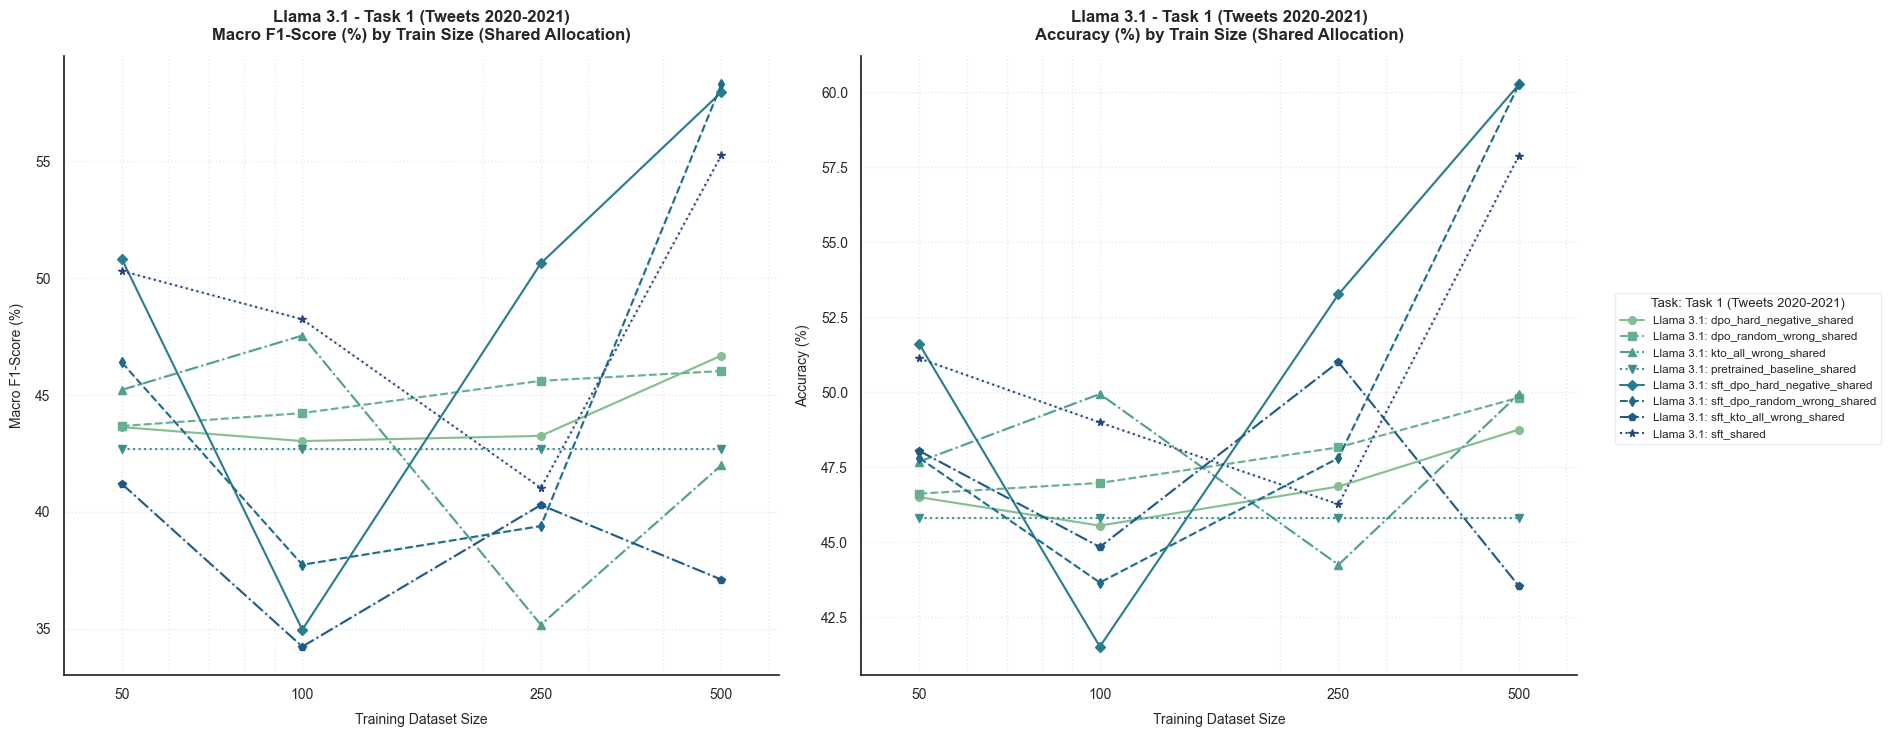

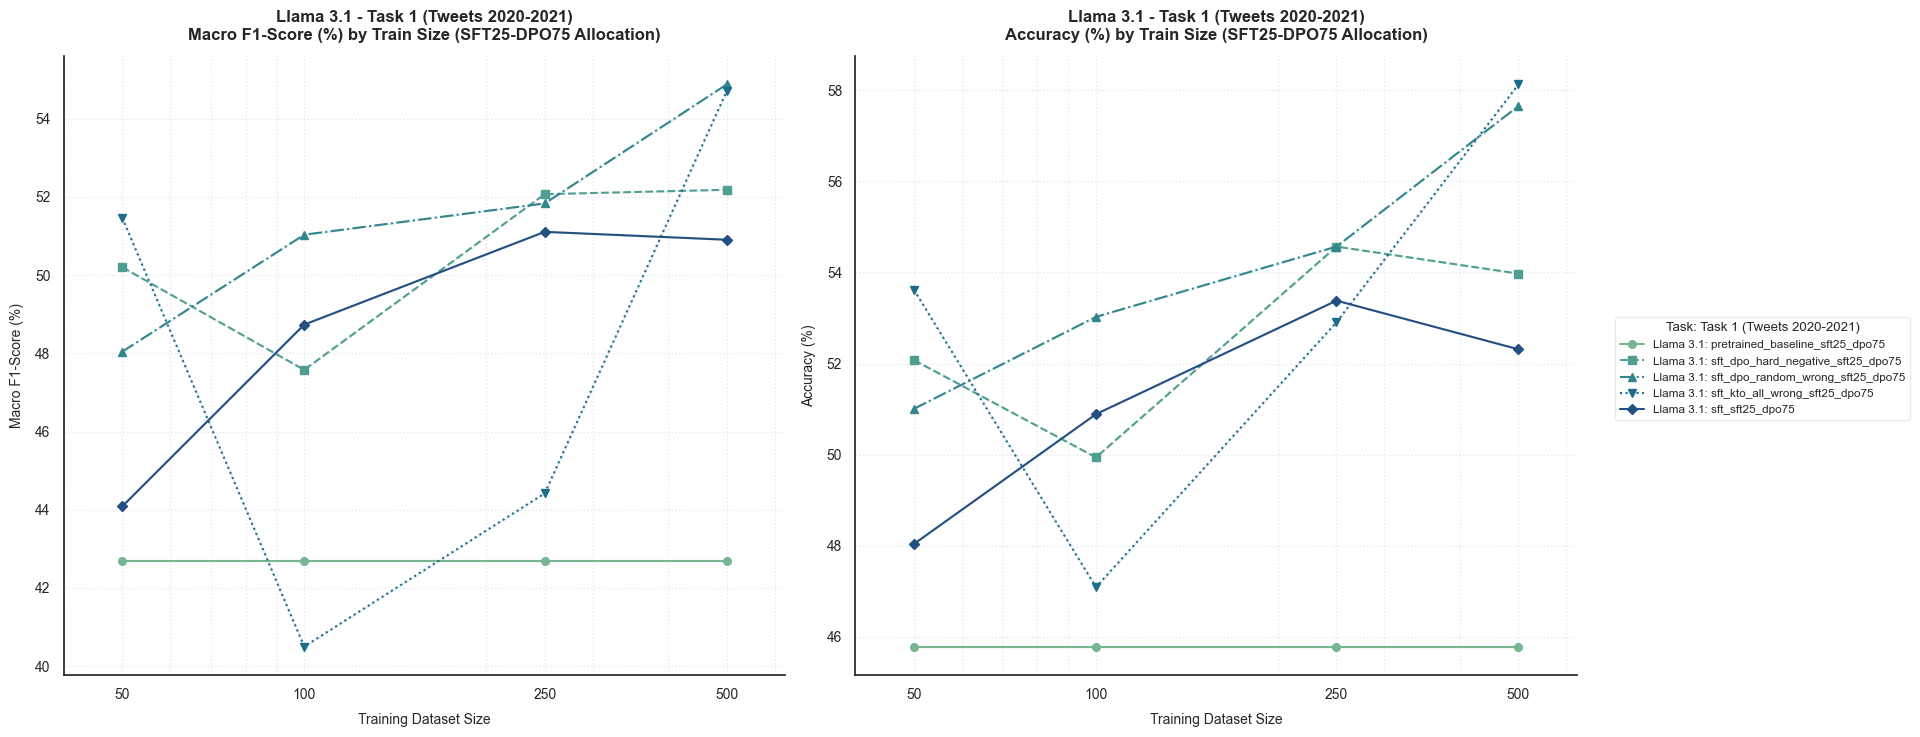

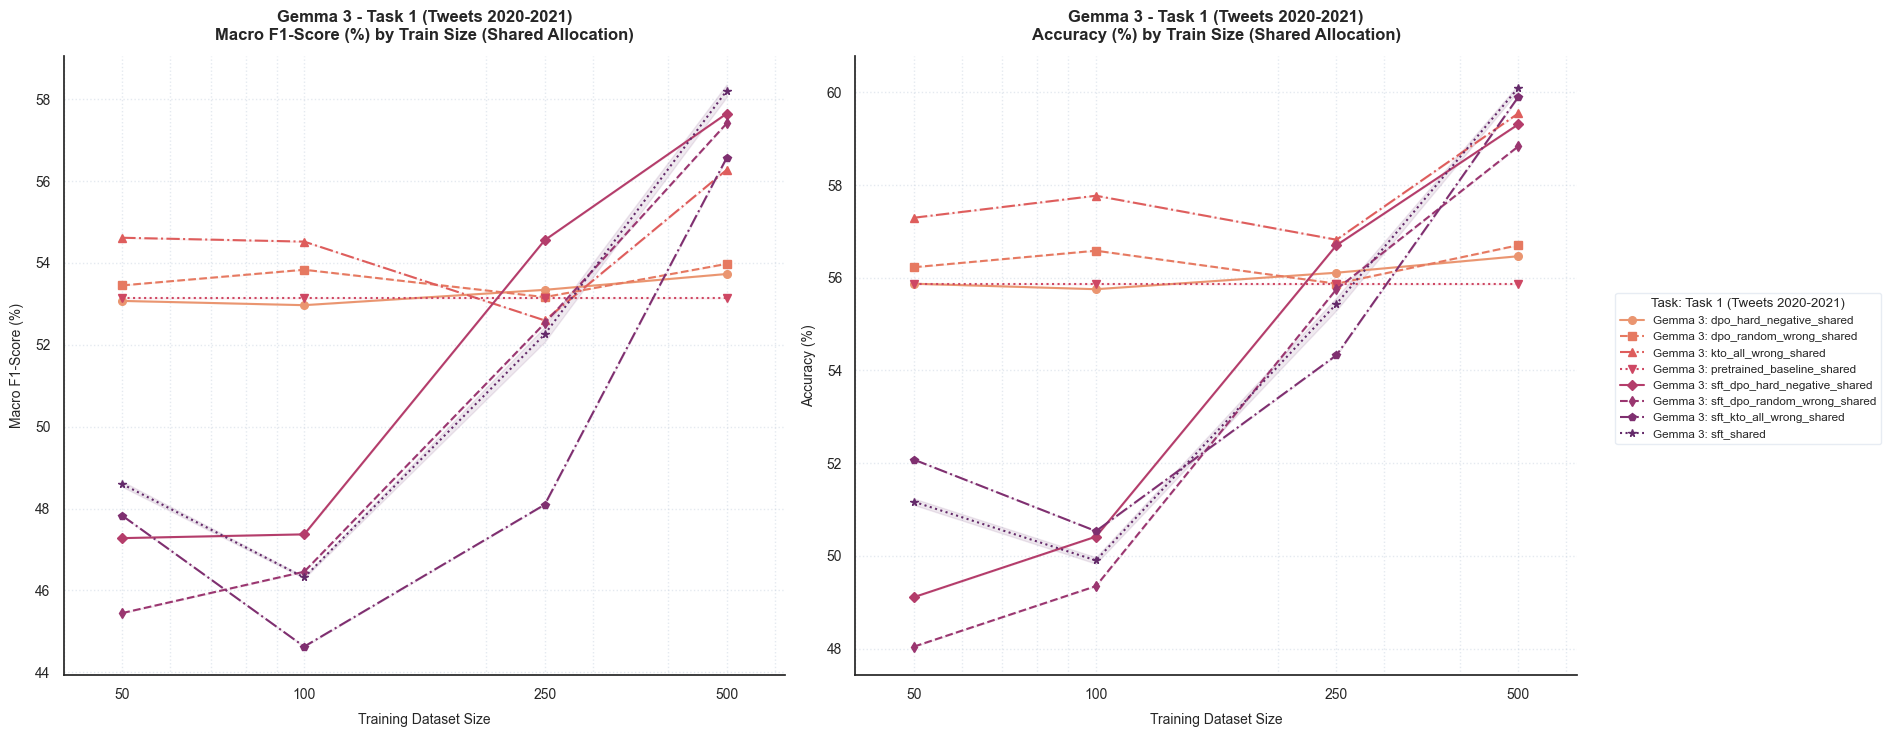

In [ ]:
plot_detailed_task_configs(WORKSPACE_DIR, 'Task 1 (Tweets 2020-2021)', 'ds1_task6')

### Task 2: News Articles (2020-2021) - Problem/Solution

=== Task 2 (News Articles 2020-2021) Performance Analysis ===


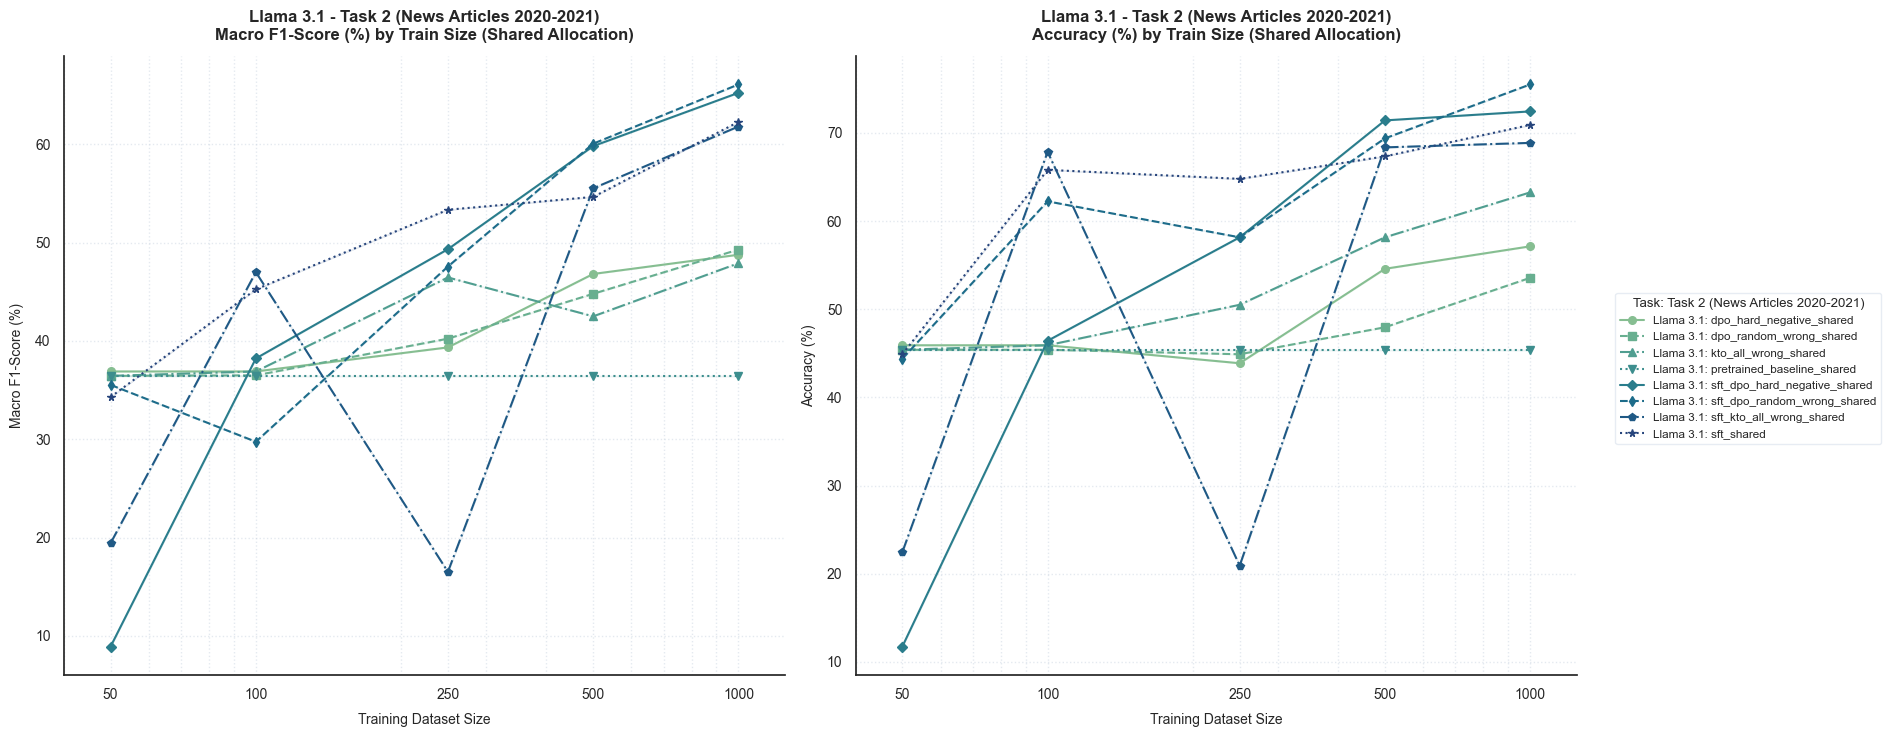

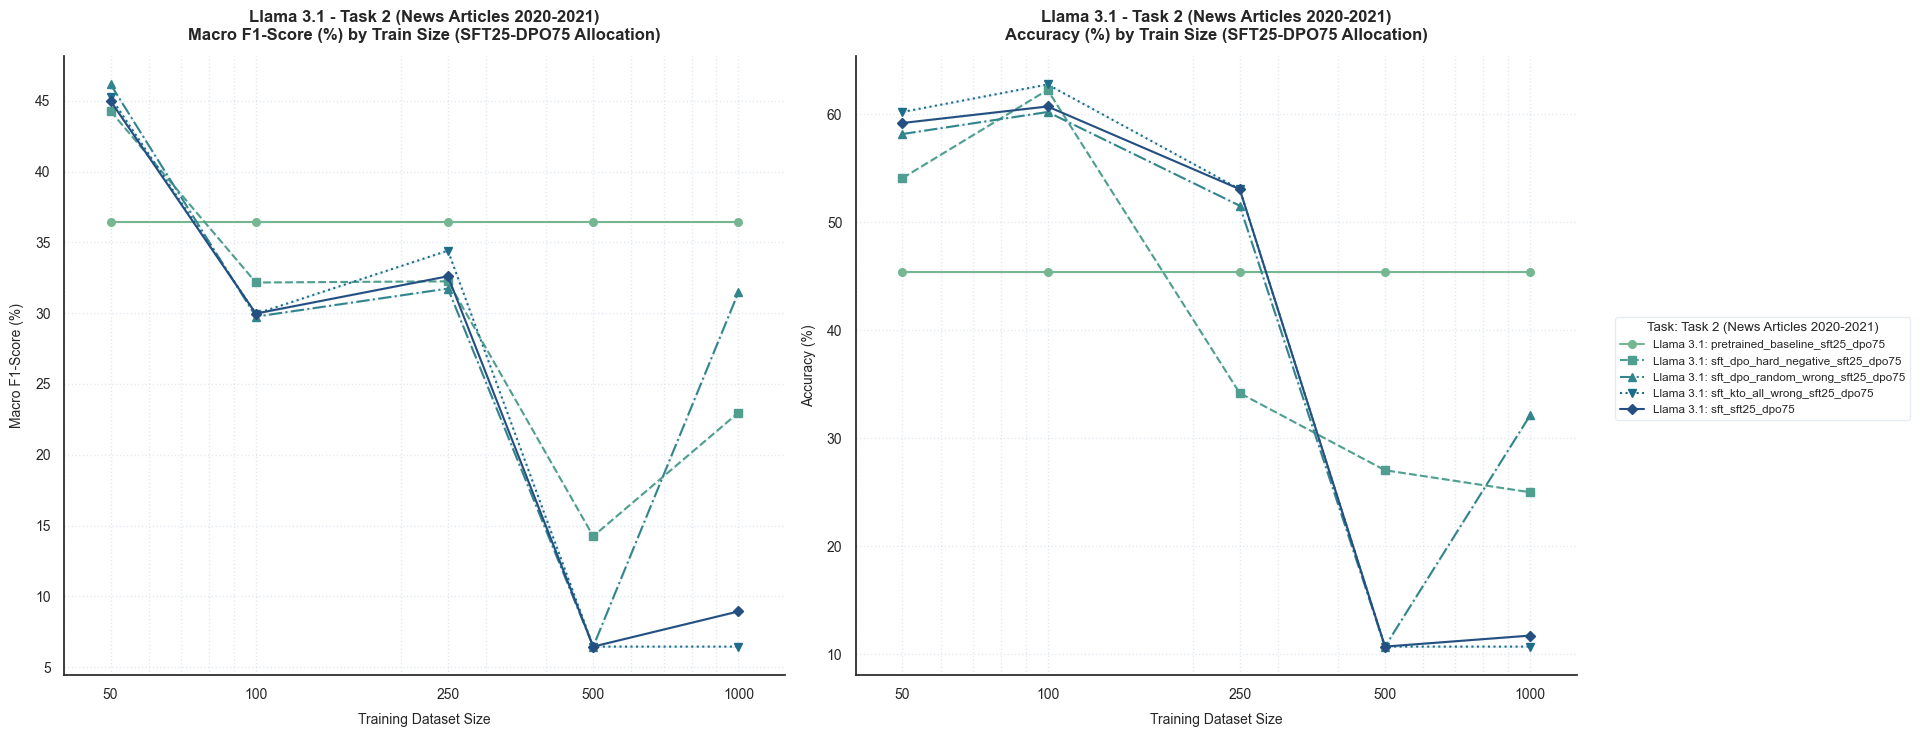

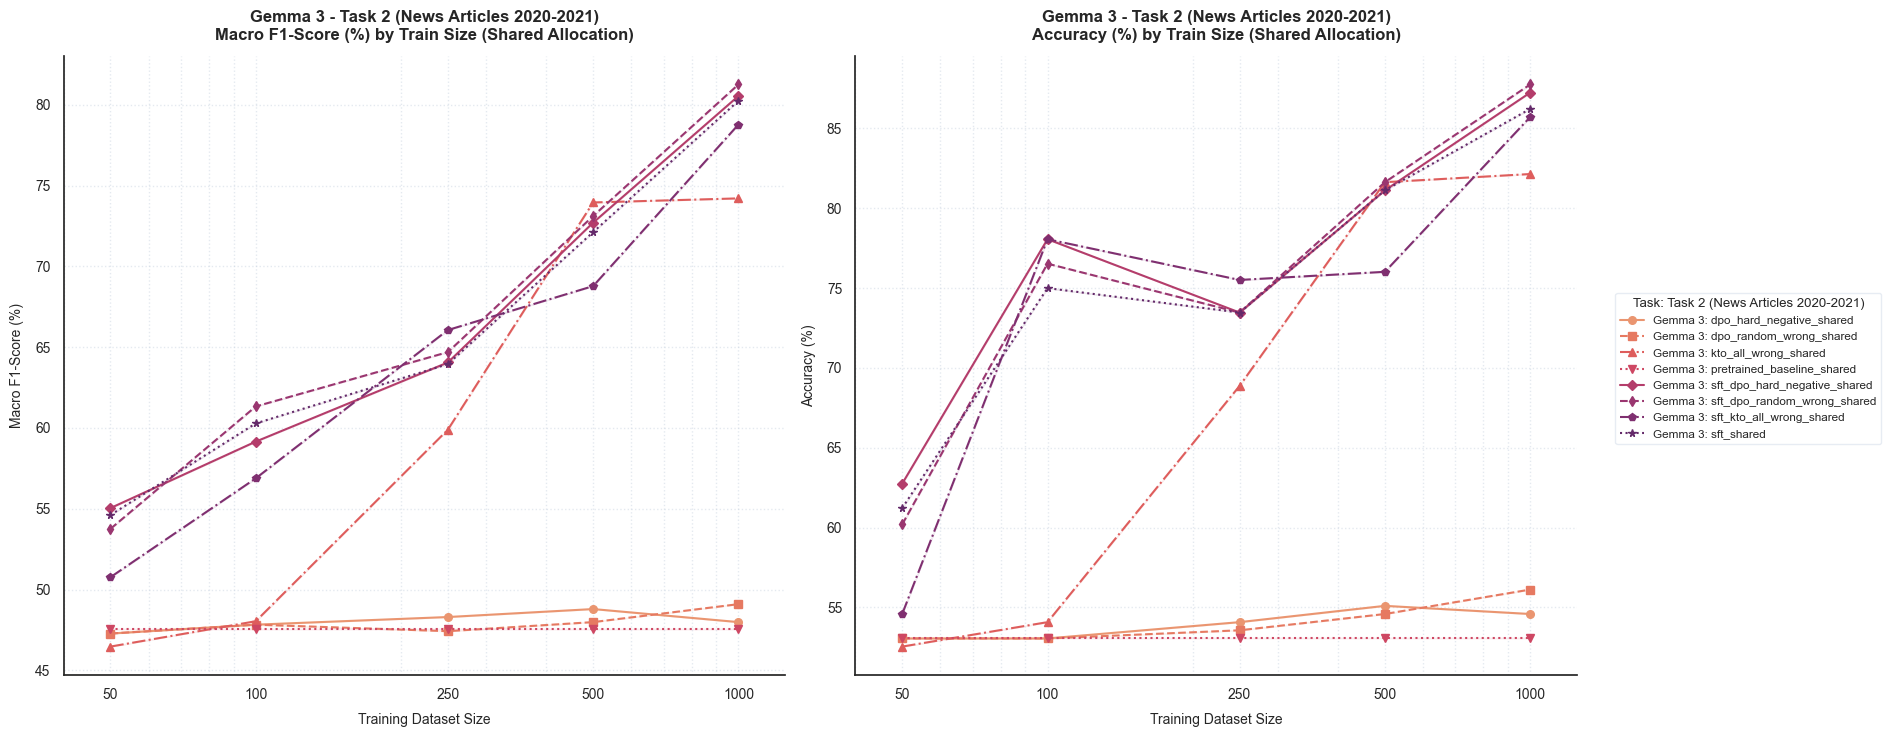

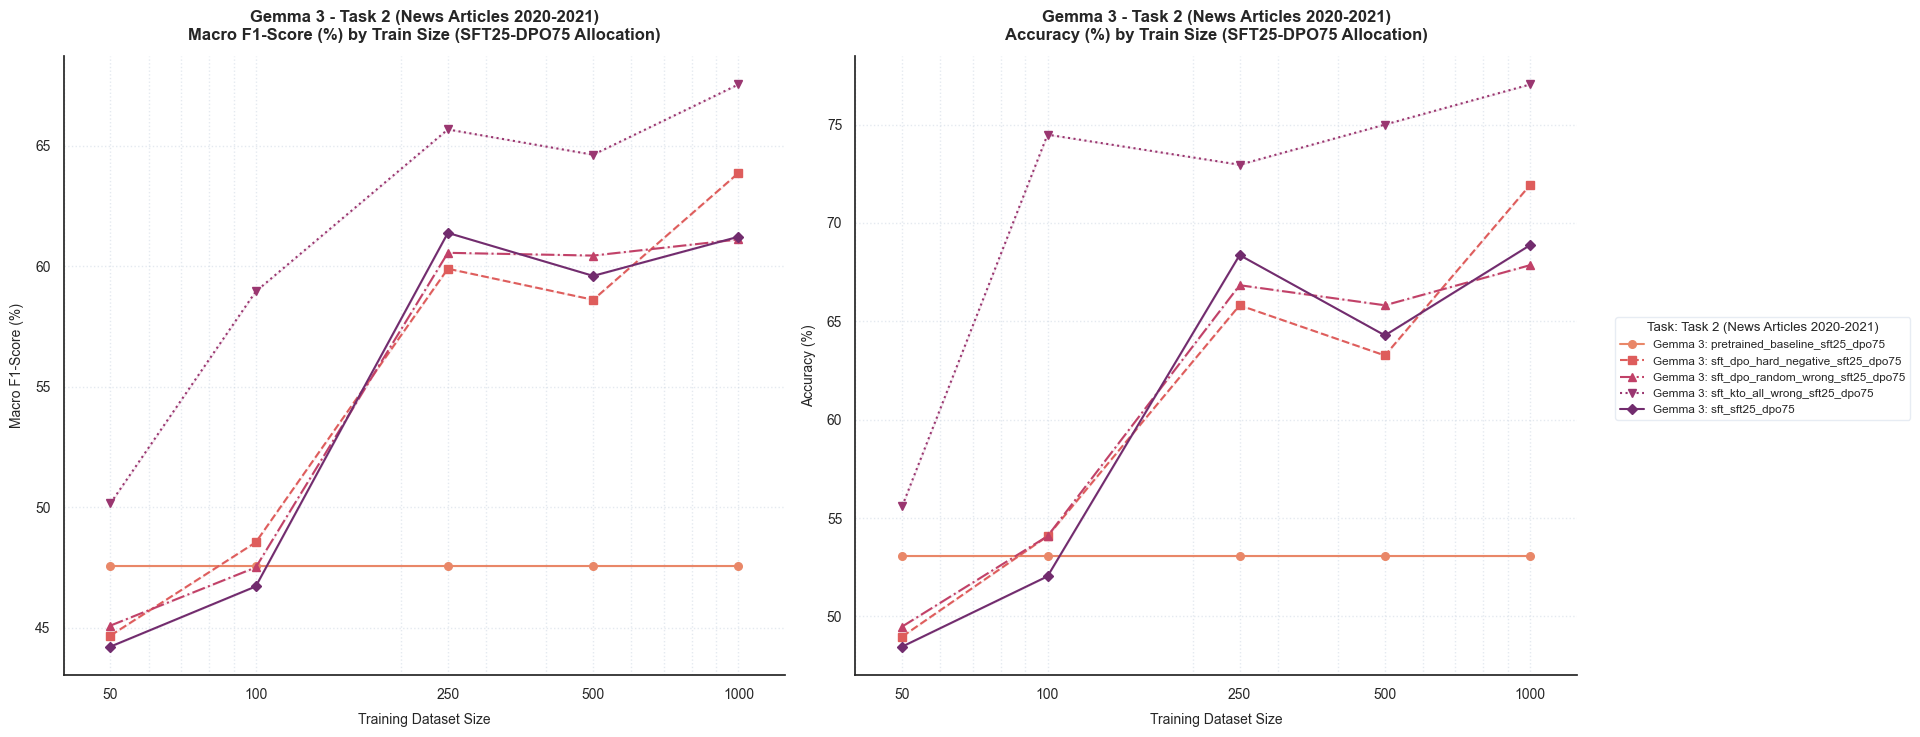

In [ ]:
plot_detailed_task_configs(WORKSPACE_DIR, 'Task 2 (News Articles 2020-2021)', 'ds4_task2')

### Task 3: Tweets (2017-2022) - Policy Frames

=== Task 3 (Tweets 2017-2022) Performance Analysis ===


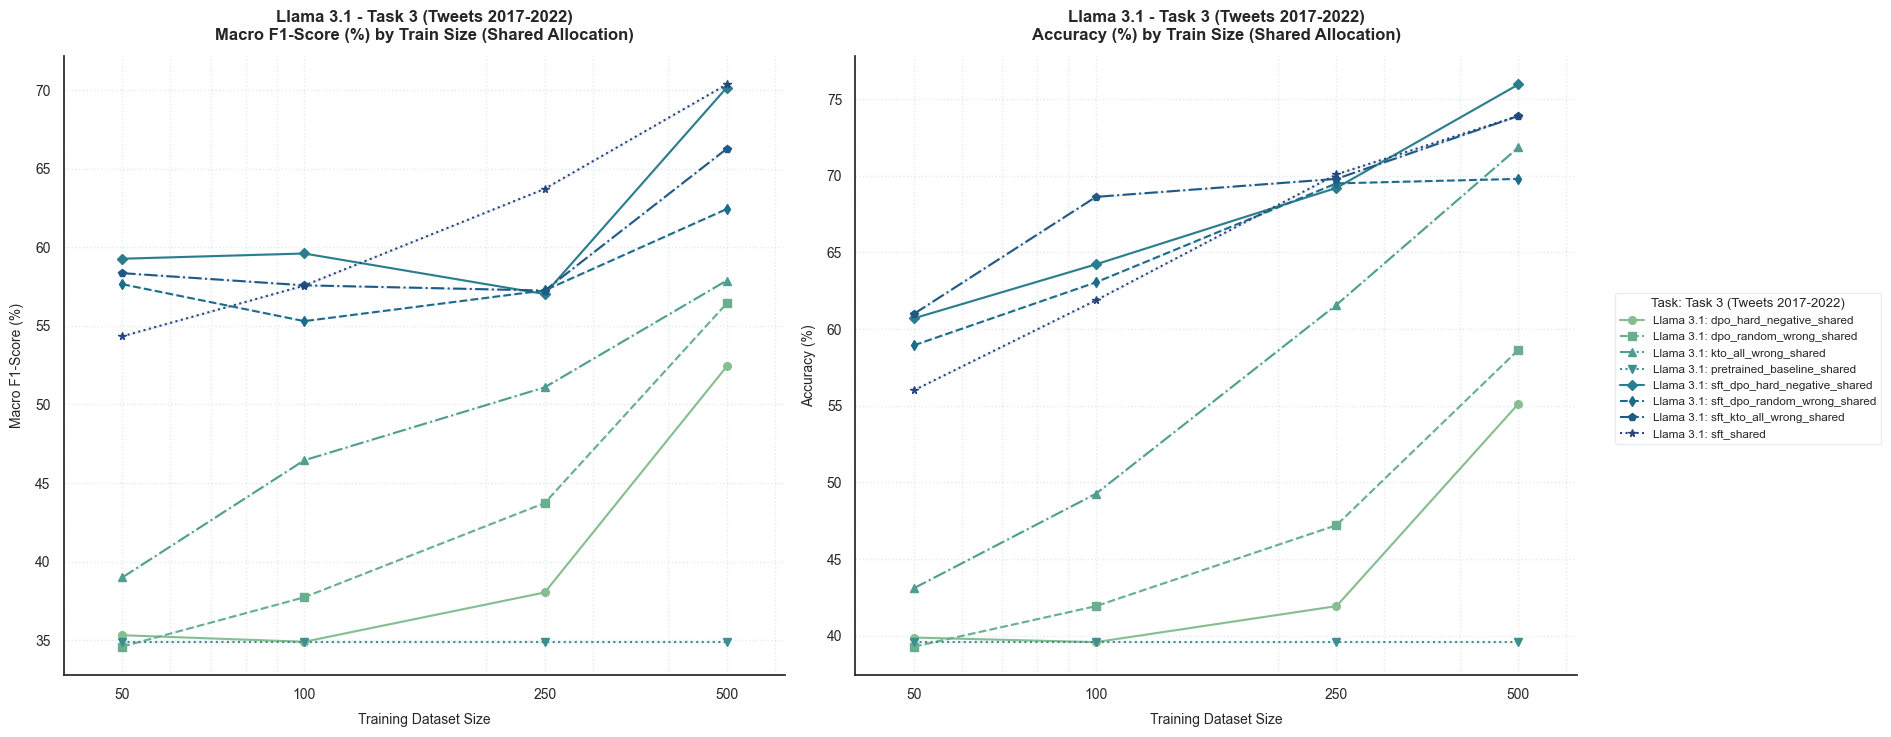

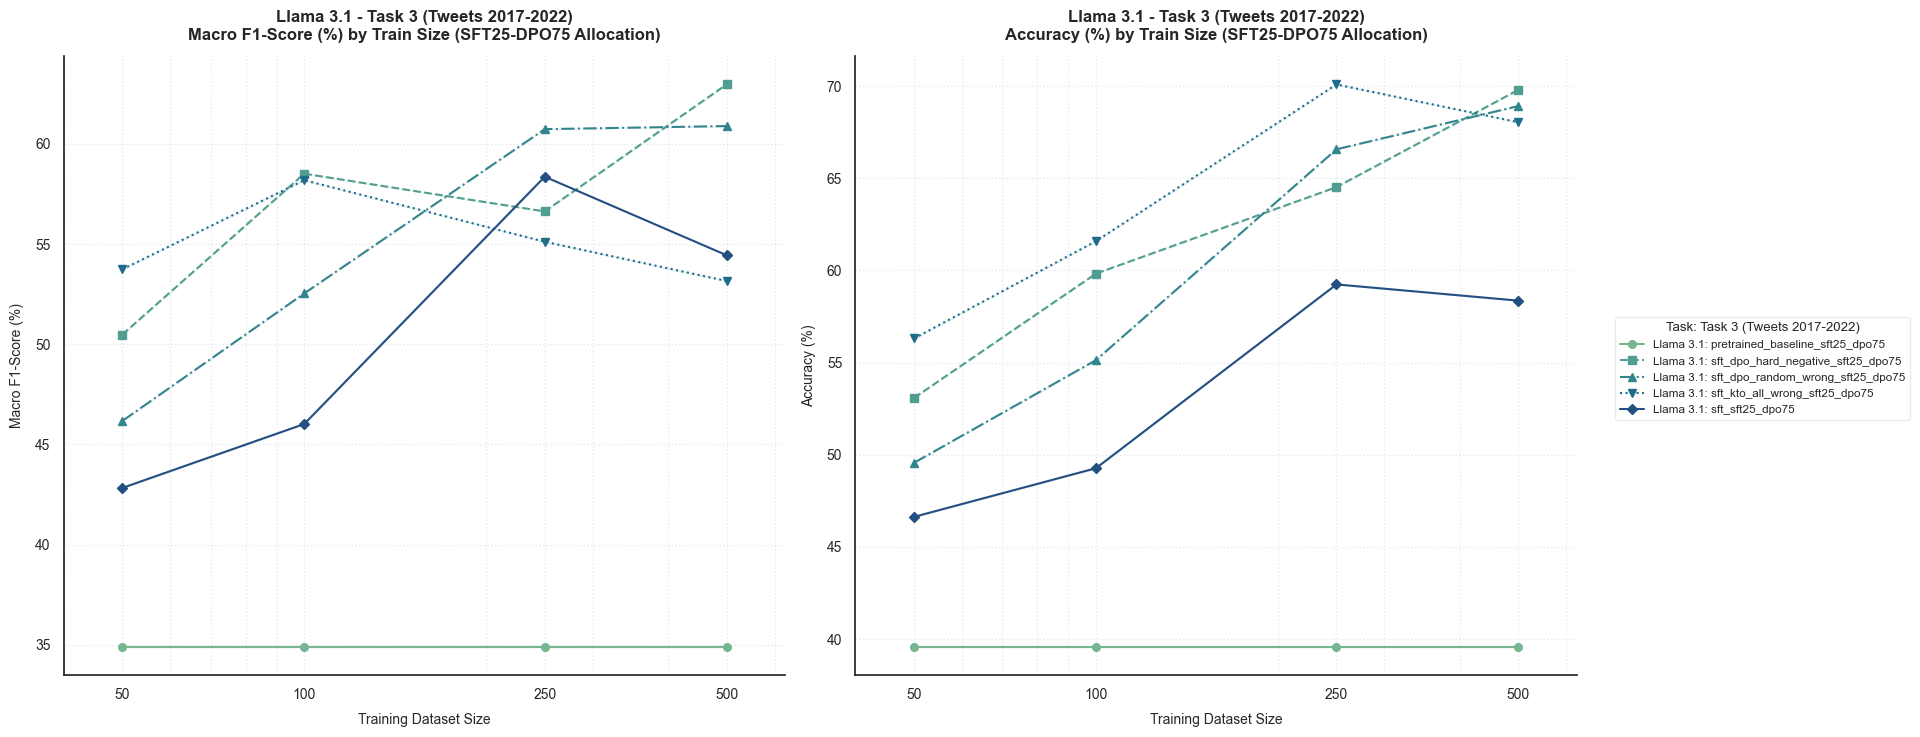

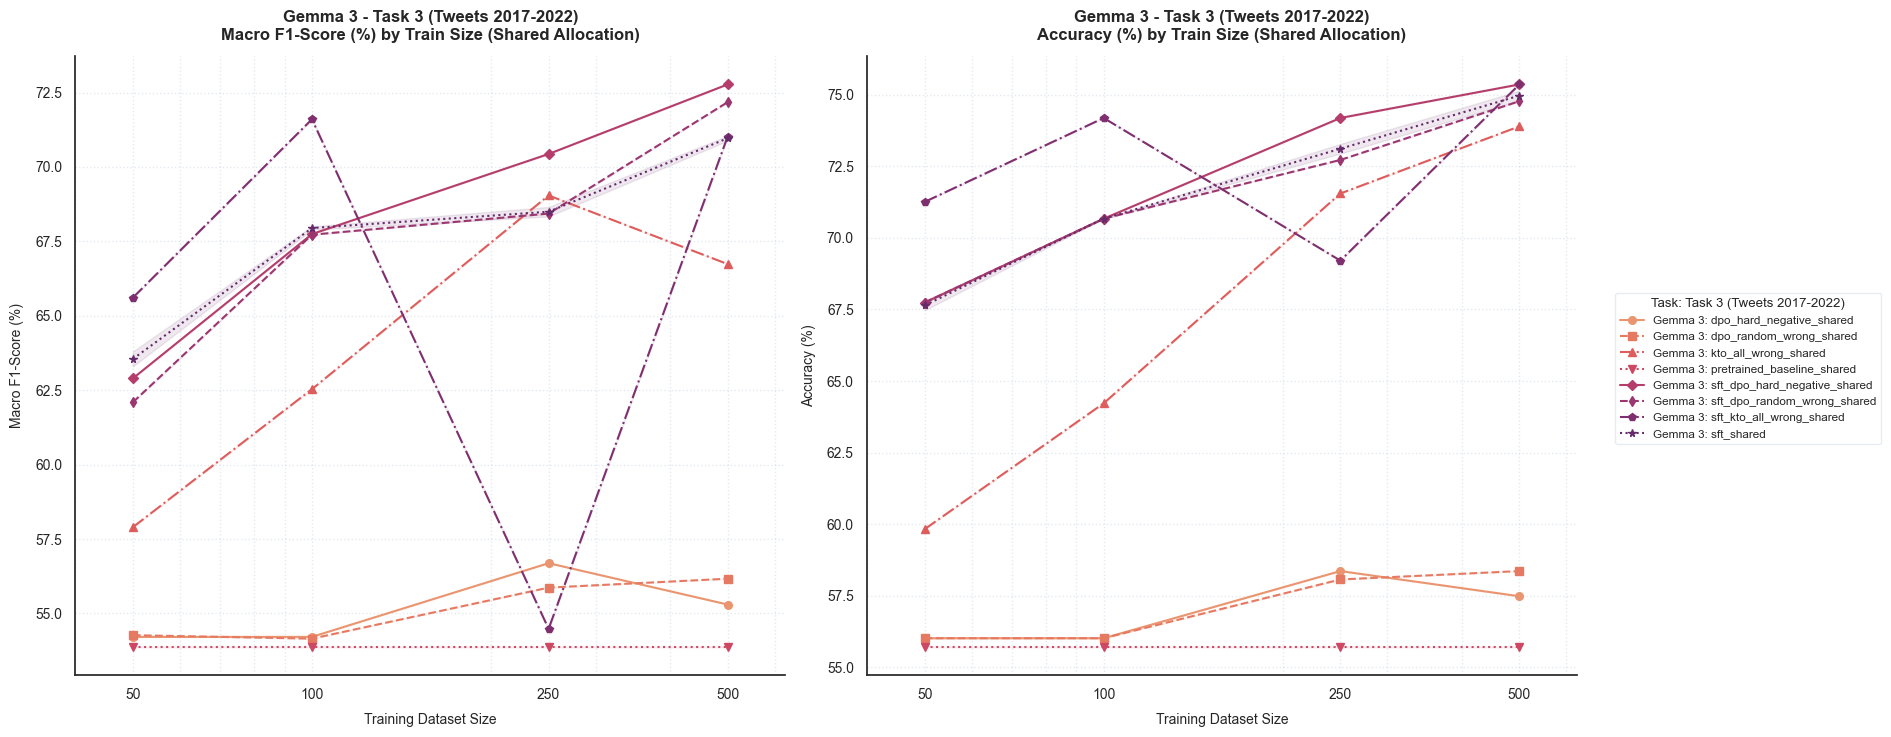

In [ ]:
plot_detailed_task_configs(WORKSPACE_DIR, 'Task 3 (Tweets 2017-2022)', 'ds3_task6')

## 5. Seed-level Confusion Matrices

This section presents the seed-level confusion matrices for the alignment runs across multiple seeds to analyze model robustness and consistency.

In [ ]:
def plot_model_seeds_confusion(workspace_dir, task_friendly, task_internal, model_friendly, model_internal, method, allocation, seeds=[11, 22, 33]):
    import matplotlib.image as mpimg
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6.2))
    fig.suptitle(f"{model_friendly} | {task_friendly} | Confusion Matrices by Seed\n{method.upper()}", 
                 fontsize=14, fontweight='bold', y=0.98)
    
    for idx, seed in enumerate(seeds):
        ax = axes[idx]
        img_path = resolve_path(workspace_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'single_adapter_multi_inference', task_internal, 'figures', f'confusion_{method}_{allocation}_seed_{seed}.png')
        if not os.path.exists(img_path):
            img_path = resolve_path(workspace_dir, 'Results_data_figures', model_internal, task_internal, 'unified_colab', 'independent_adapters', task_internal, 'figures', f'confusion_{method}_{allocation}_seed_{seed}.png')
        
        if os.path.exists(img_path):
            try:
                img = mpimg.imread(img_path)
                ax.imshow(img)
                ax.axis('off')
                ax.set_title(f"Seed {seed}", fontsize=11, fontweight='bold', pad=8)
            except Exception as e:
                ax.text(0.5, 0.5, f"Error loading image:\n{e}", ha='center', va='center')
                ax.axis('off')
        else:
            ax.text(0.5, 0.5, f"Confusion matrix PNG\nnot found for Seed {seed}", ha='center', va='center')
            ax.axis('off')
            
    plt.tight_layout()
    plt.show()

### Task 1: Tweets (2020-2021) - Policy Frames

=== Llama 3.1 8B SFT Shared (Confusion Matrices) ===


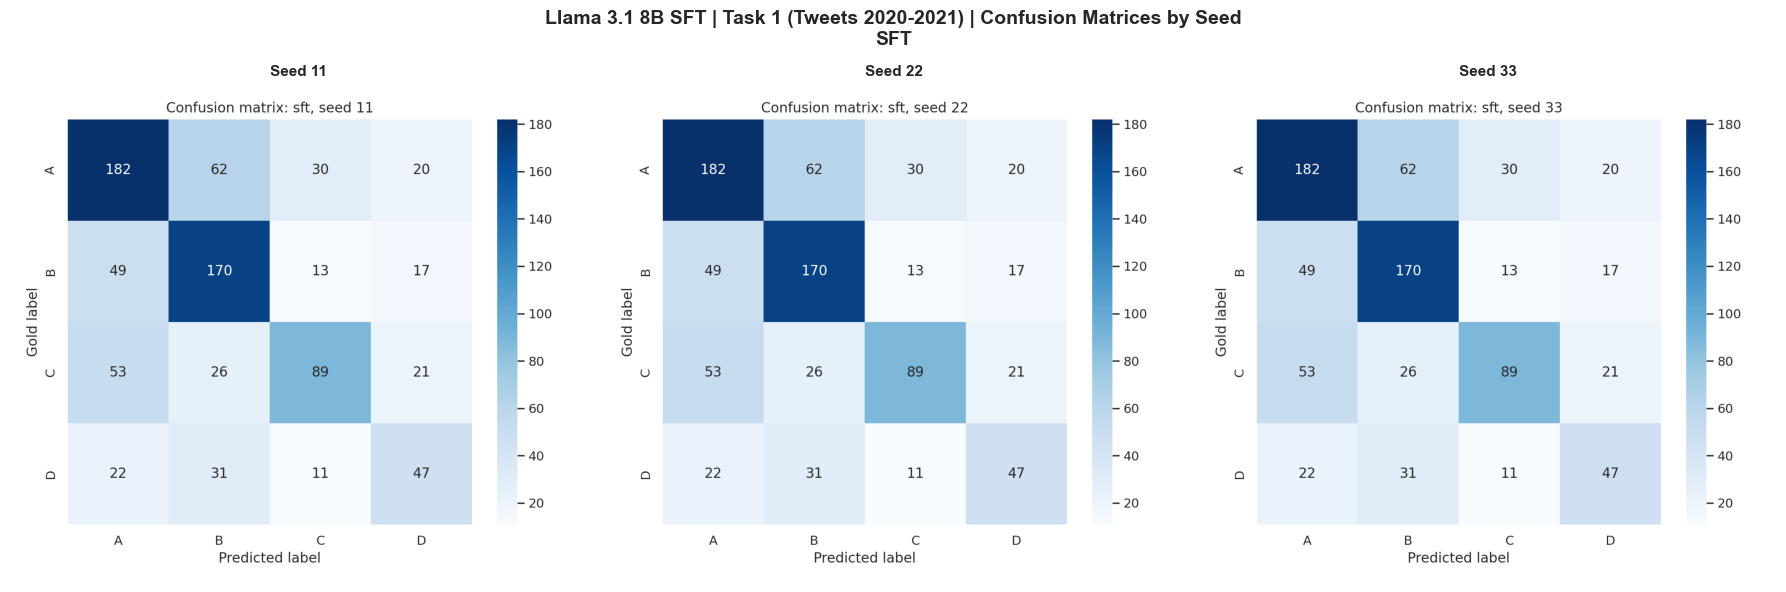

=== Llama 3.1 8B SFT+DPO Shared (Confusion Matrices) ===


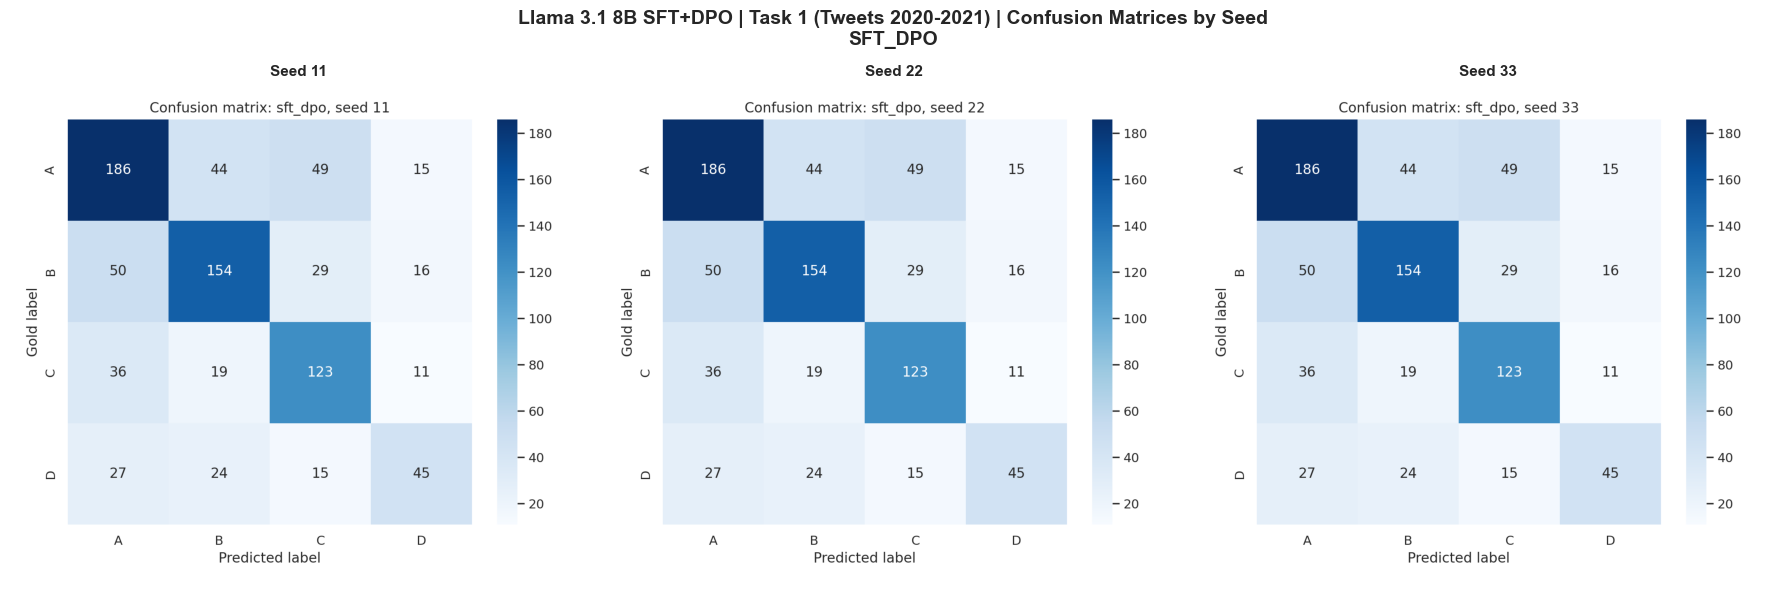

=== Gemma 3 SFT Shared (Confusion Matrices) ===


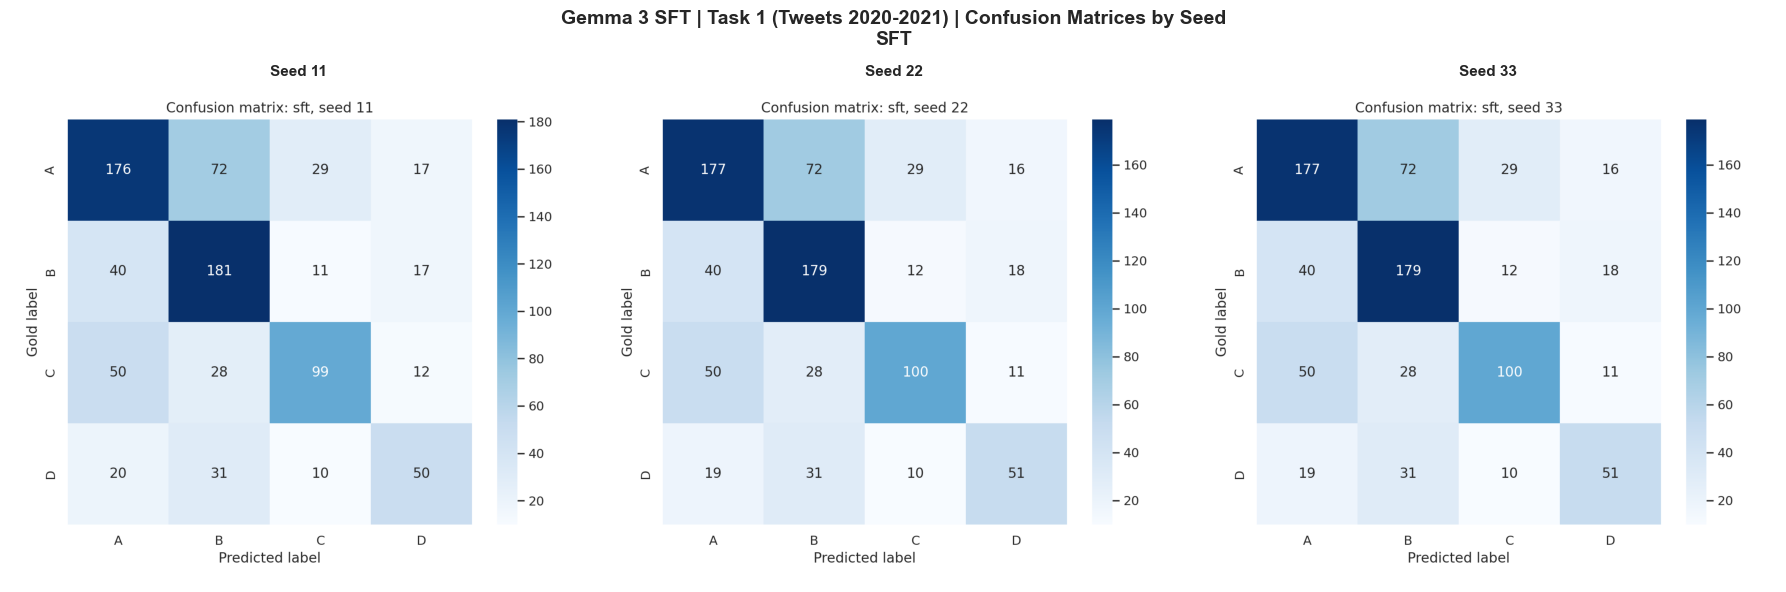

=== Gemma 3 SFT+DPO Shared (Confusion Matrices) ===


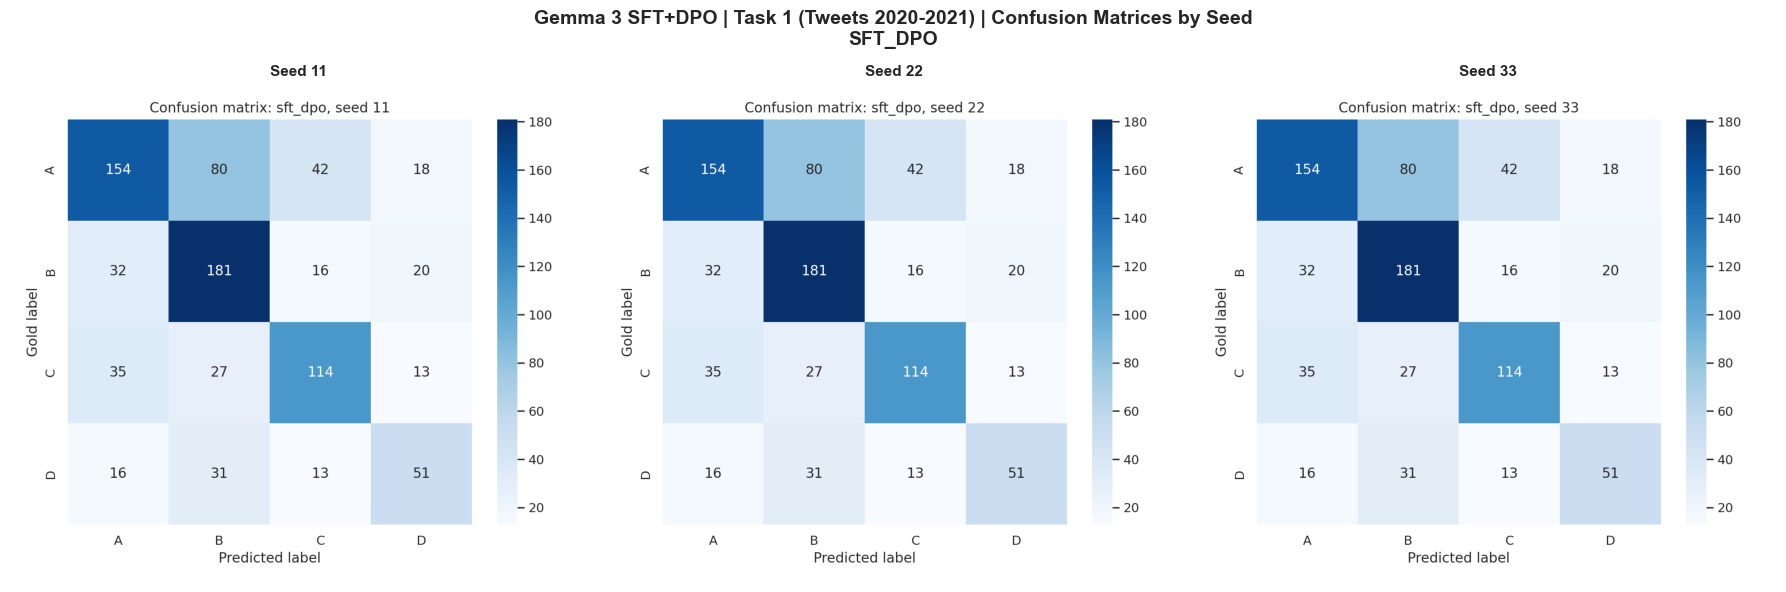

In [ ]:
print("=== Llama 3.1 8B SFT Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 1 (Tweets 2020-2021)', 'ds1_task6', 'Llama 3.1 8B SFT', 'llama31', 'sft', 'shared')

print("=== Llama 3.1 8B SFT+DPO Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 1 (Tweets 2020-2021)', 'ds1_task6', 'Llama 3.1 8B SFT+DPO', 'llama31', 'sft_dpo', 'shared')

print("=== Gemma 3 SFT Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 1 (Tweets 2020-2021)', 'ds1_task6', 'Gemma 3 SFT', 'gemma3', 'sft', 'shared')

print("=== Gemma 3 SFT+DPO Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 1 (Tweets 2020-2021)', 'ds1_task6', 'Gemma 3 SFT+DPO', 'gemma3', 'sft_dpo', 'shared')

### Task 2: News Articles (2020-2021) - Problem/Solution

=== Llama 3.1 8B SFT Shared (Confusion Matrices) ===


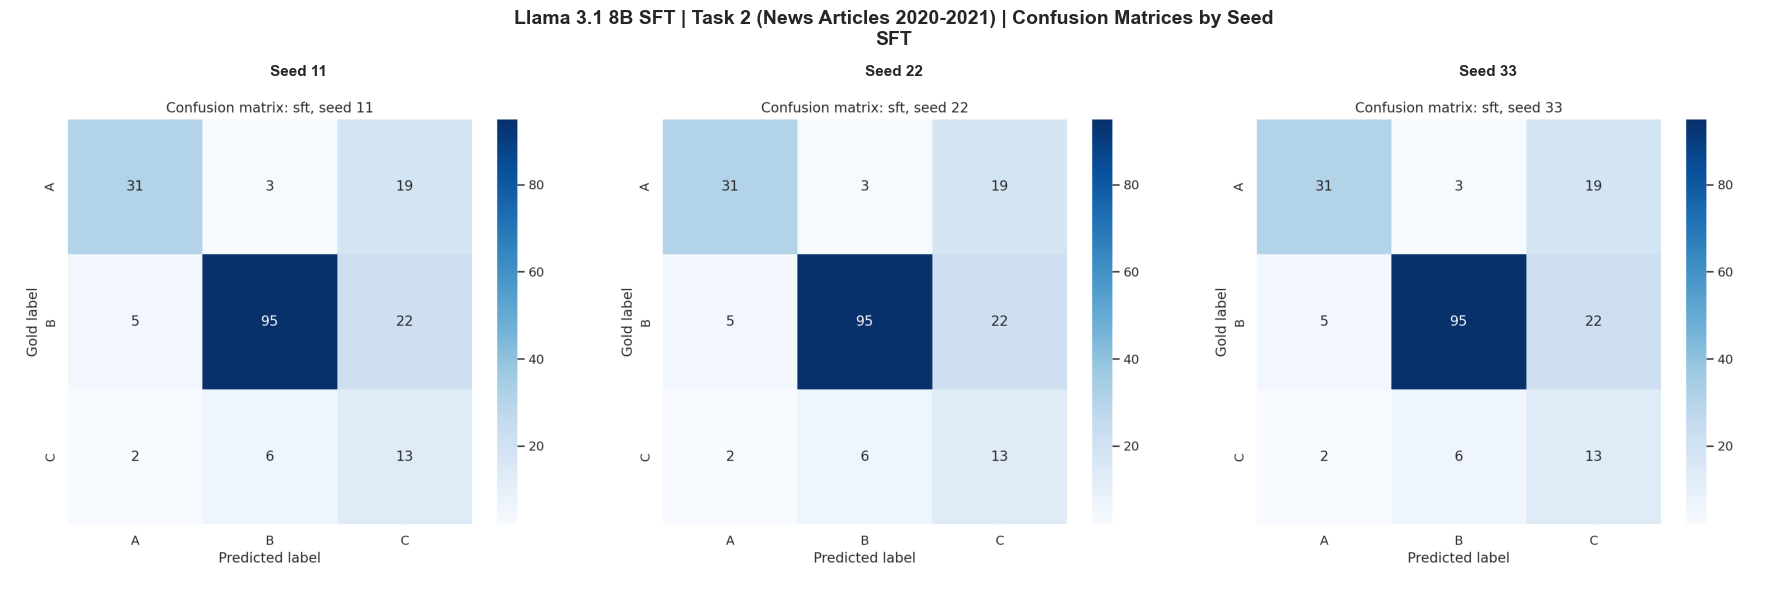

=== Llama 3.1 8B SFT+DPO Shared (Confusion Matrices) ===


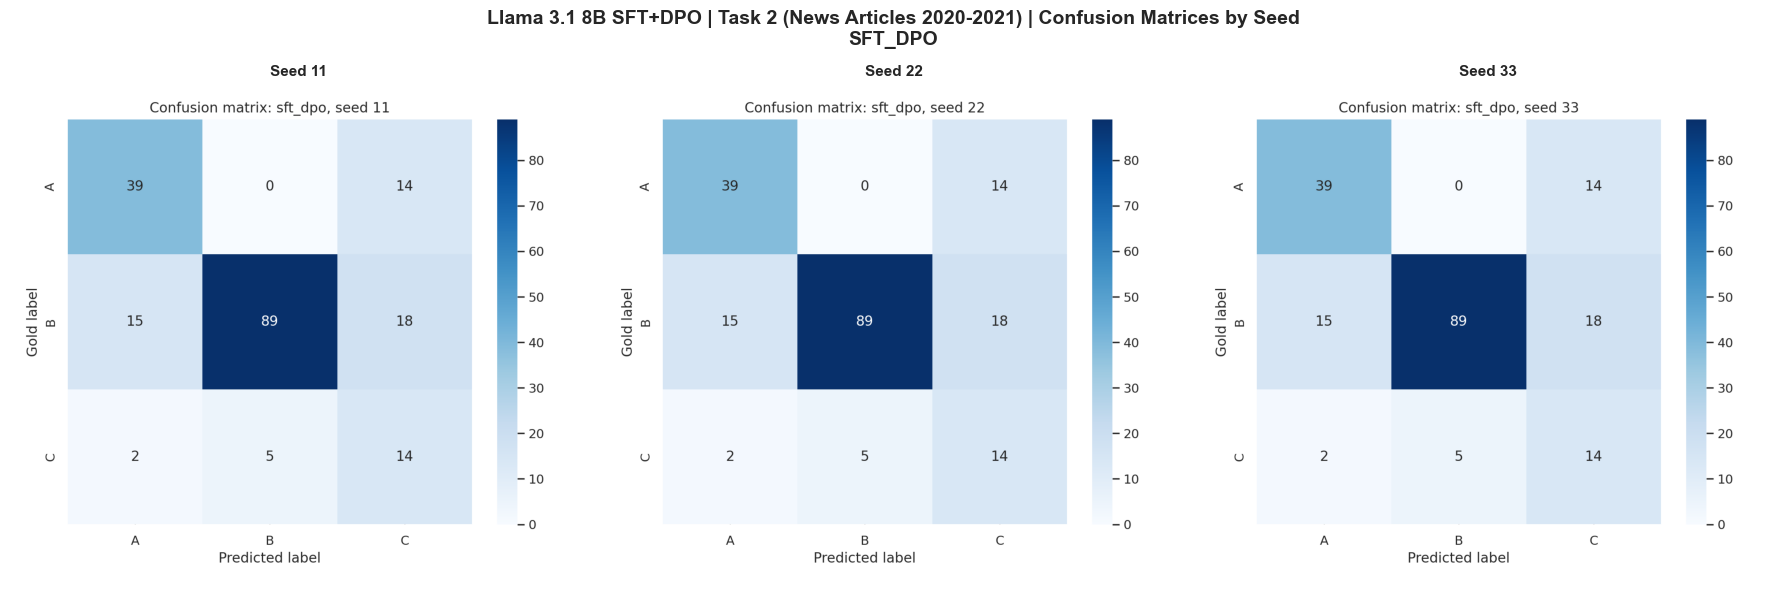

=== Gemma 3 SFT Shared (Confusion Matrices) ===


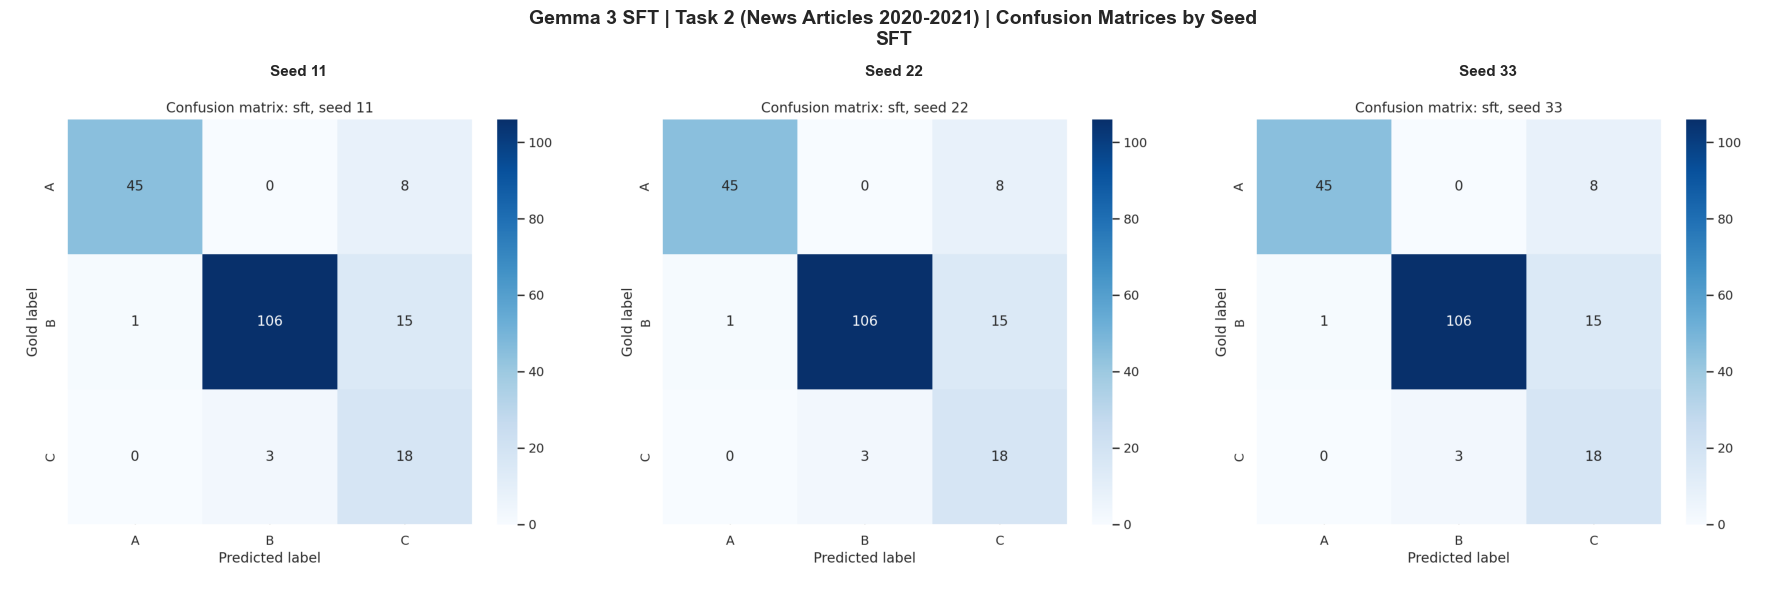

=== Gemma 3 SFT+DPO Shared (Confusion Matrices) ===


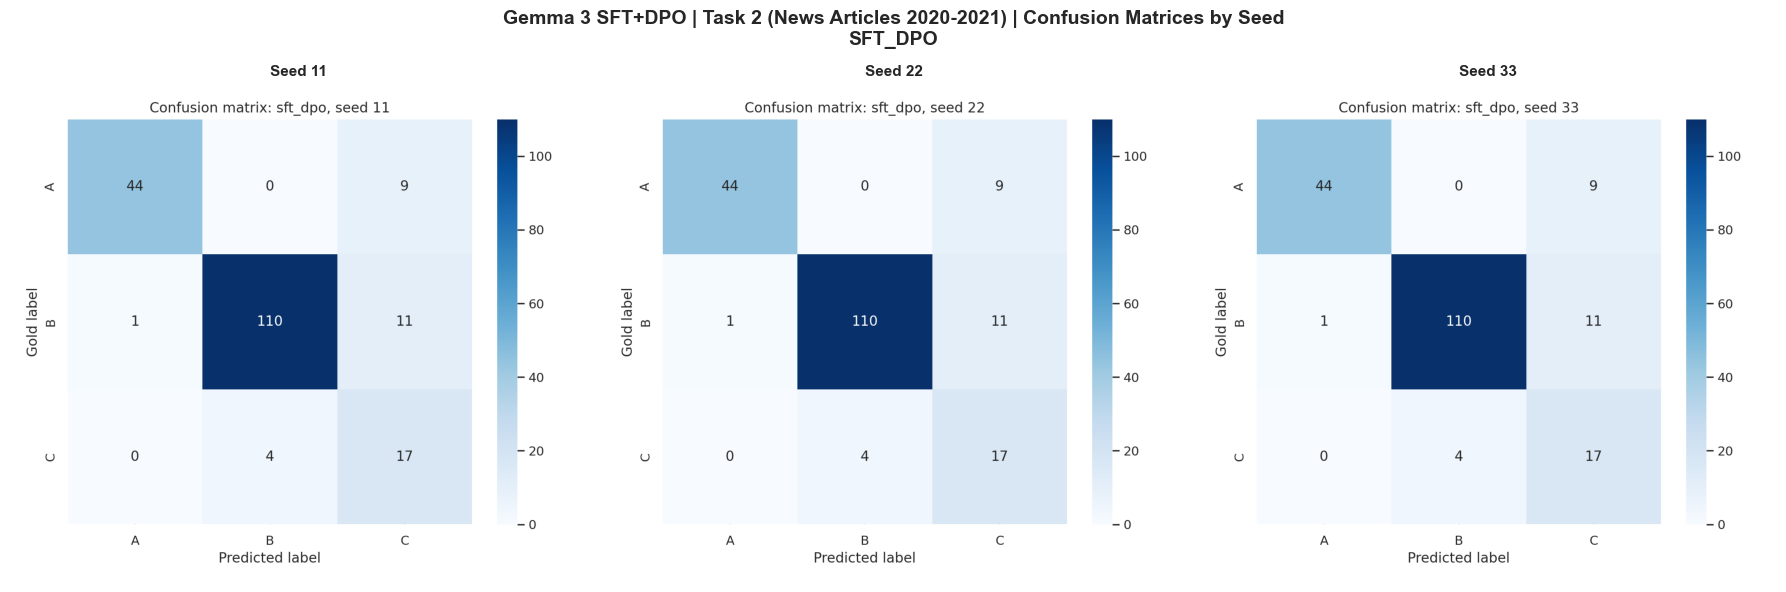

In [ ]:
print("=== Llama 3.1 8B SFT Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 2 (News Articles 2020-2021)', 'ds4_task2', 'Llama 3.1 8B SFT', 'llama31', 'sft', 'shared')

print("=== Llama 3.1 8B SFT+DPO Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 2 (News Articles 2020-2021)', 'ds4_task2', 'Llama 3.1 8B SFT+DPO', 'llama31', 'sft_dpo', 'shared')

print("=== Gemma 3 SFT Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 2 (News Articles 2020-2021)', 'ds4_task2', 'Gemma 3 SFT', 'gemma3', 'sft', 'shared')

print("=== Gemma 3 SFT+DPO Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 2 (News Articles 2020-2021)', 'ds4_task2', 'Gemma 3 SFT+DPO', 'gemma3', 'sft_dpo', 'shared')

### Task 3: Tweets (2017-2022) - Policy Frames

=== Llama 3.1 8B SFT Shared (Confusion Matrices) ===


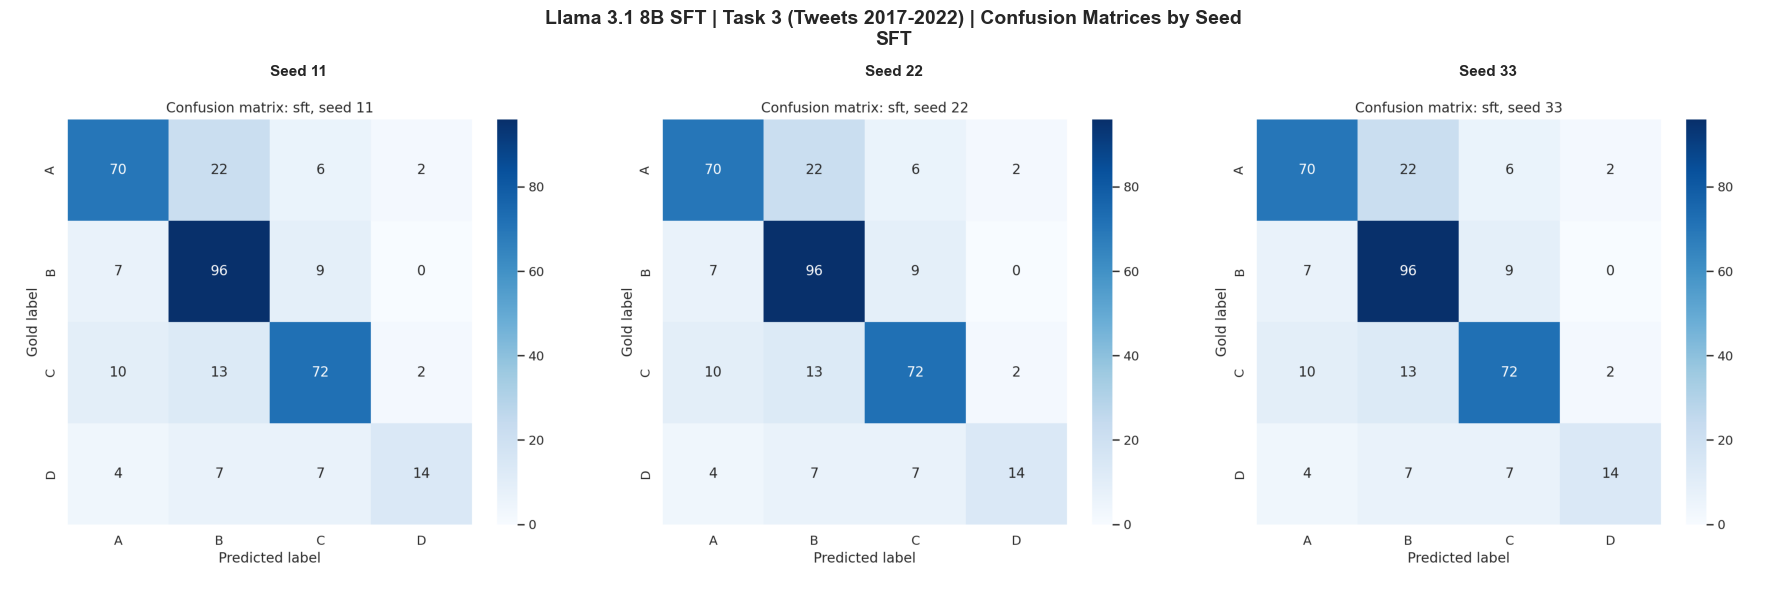

=== Llama 3.1 8B SFT+DPO Shared (Confusion Matrices) ===


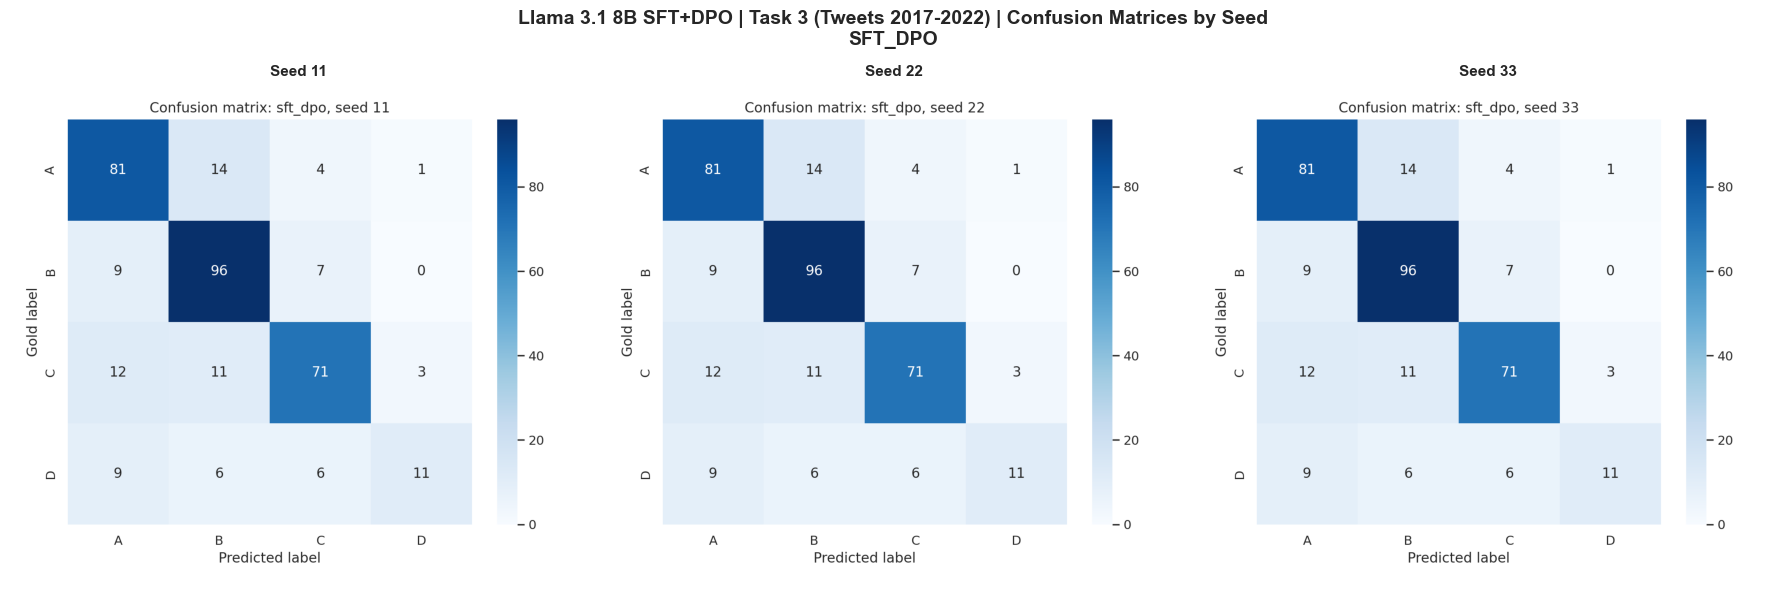

=== Gemma 3 SFT Shared (Confusion Matrices) ===


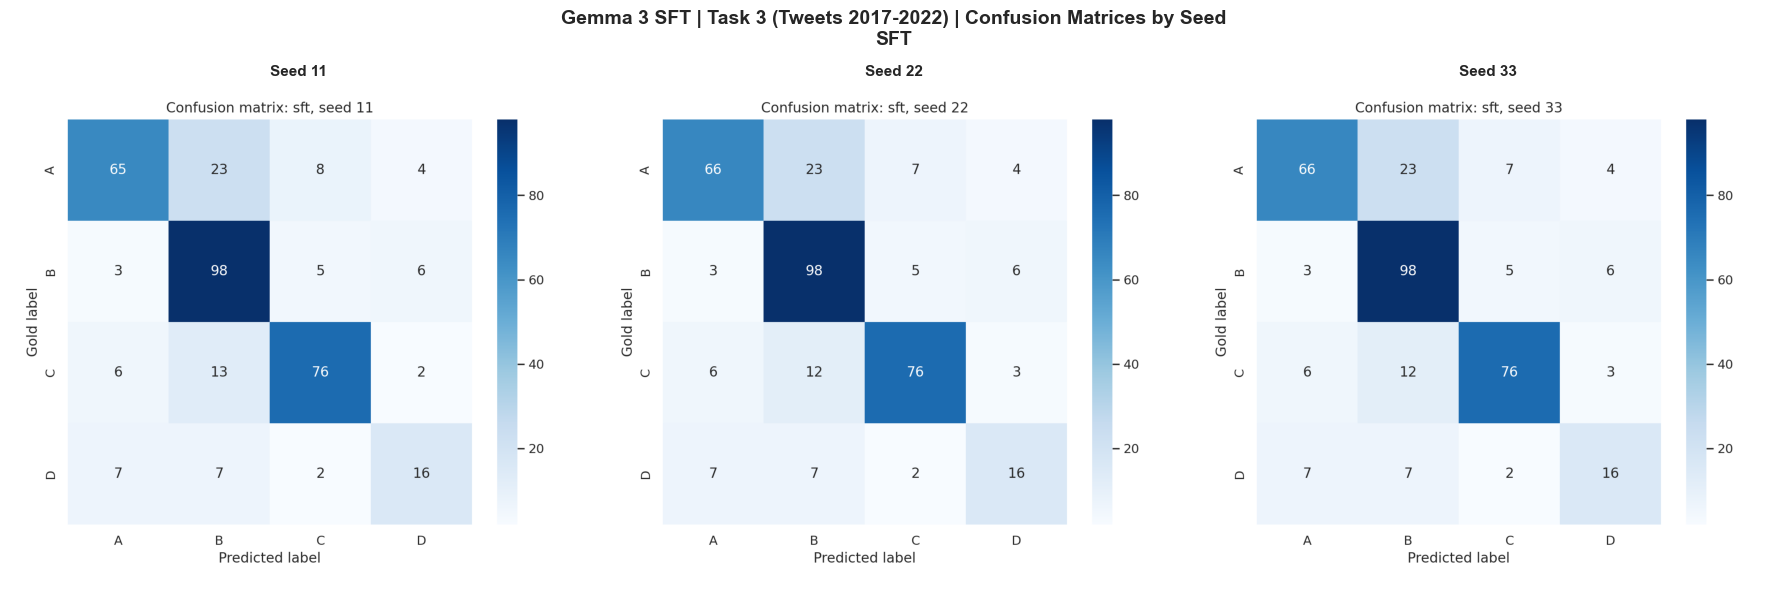

=== Gemma 3 SFT+DPO Shared (Confusion Matrices) ===


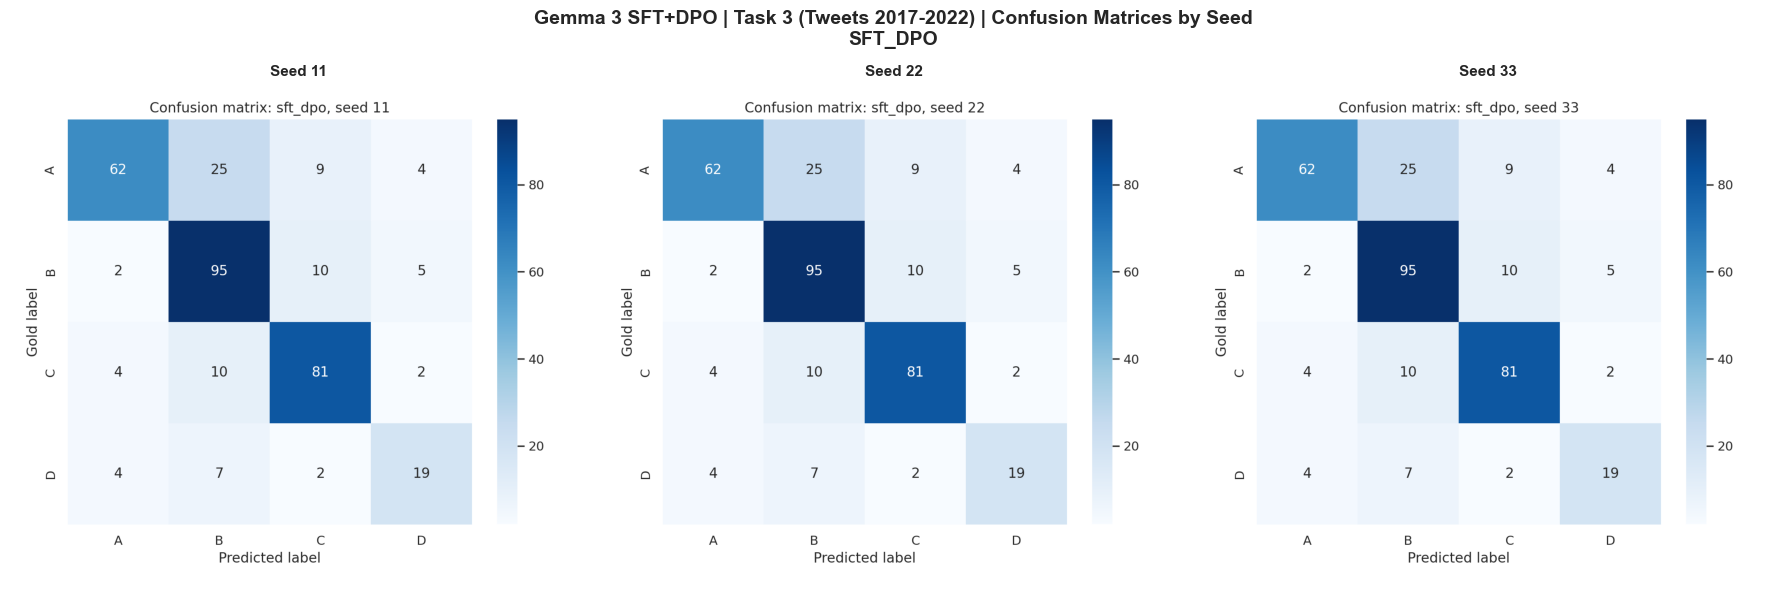

In [ ]:
print("=== Llama 3.1 8B SFT Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 3 (Tweets 2017-2022)', 'ds3_task6', 'Llama 3.1 8B SFT', 'llama31', 'sft', 'shared')

print("=== Llama 3.1 8B SFT+DPO Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 3 (Tweets 2017-2022)', 'ds3_task6', 'Llama 3.1 8B SFT+DPO', 'llama31', 'sft_dpo', 'shared')

print("=== Gemma 3 SFT Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 3 (Tweets 2017-2022)', 'ds3_task6', 'Gemma 3 SFT', 'gemma3', 'sft', 'shared')

print("=== Gemma 3 SFT+DPO Shared (Confusion Matrices) ===")
plot_model_seeds_confusion(WORKSPACE_DIR, 'Task 3 (Tweets 2017-2022)', 'ds3_task6', 'Gemma 3 SFT+DPO', 'gemma3', 'sft_dpo', 'shared')

## 6. SFT & Preference Alignment Training Curves (Single Adapter Multi-Inference)

This section displays the training curves (accuracy and Macro F1-score) over training steps for Llama 3.1 8B on Task 3.

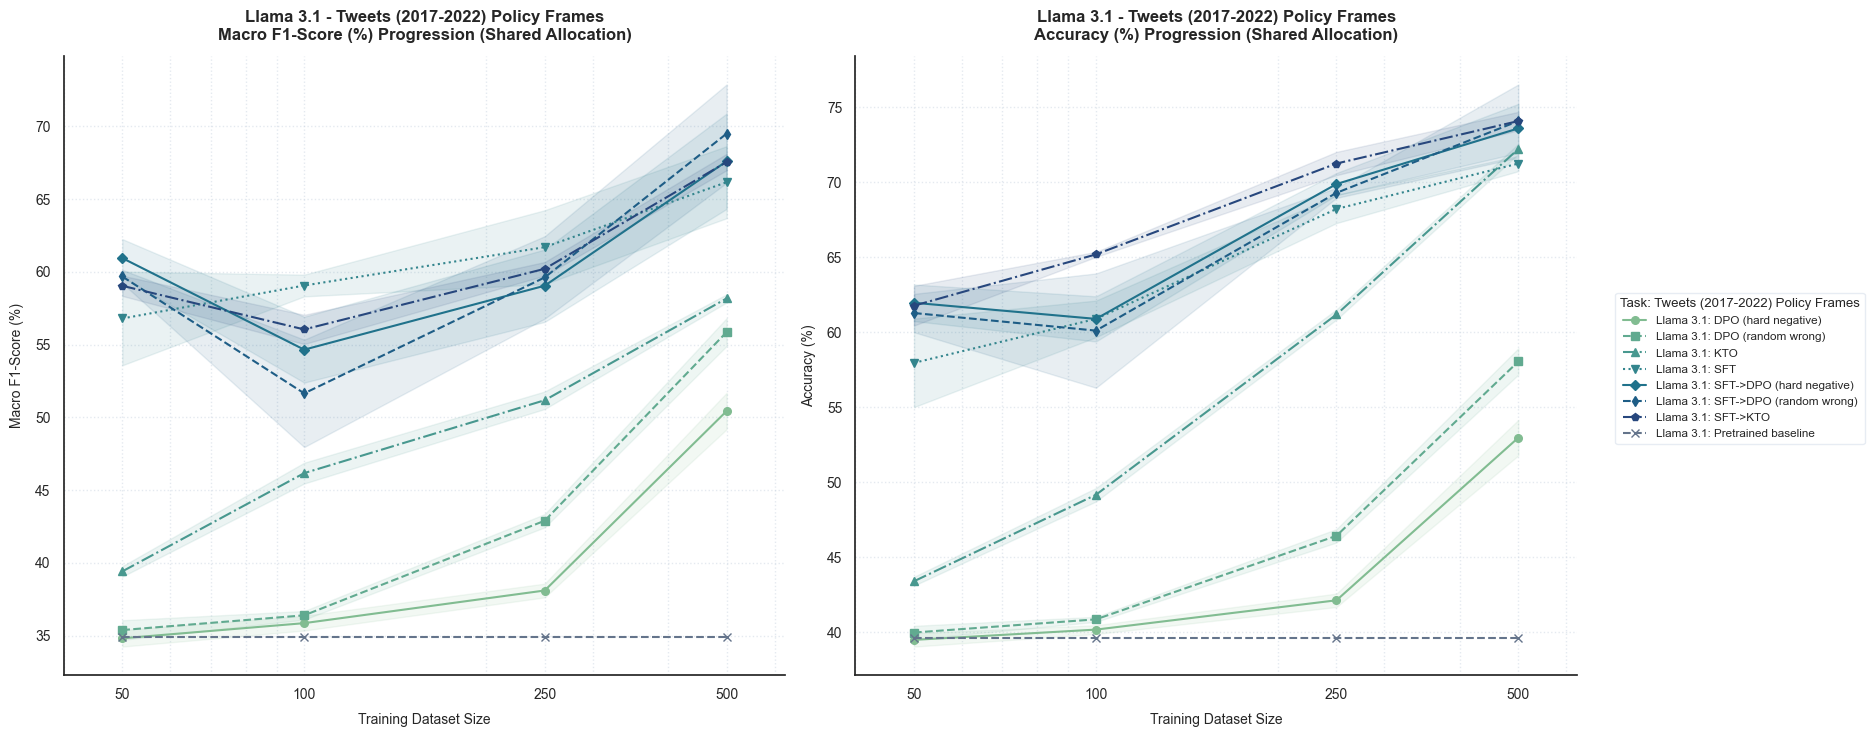

Configuration,Train Size,Macro F1-Score (%),Accuracy (%)
dpo_hard_negative_shared,50,34.82% ± 0.57%,39.49% ± 0.45%
dpo_hard_negative_shared,100,35.86% ± 0.51%,40.18% ± 0.29%
dpo_hard_negative_shared,250,38.11% ± 0.47%,42.13% ± 0.45%
dpo_hard_negative_shared,500,50.44% ± 1.25%,52.98% ± 1.19%
dpo_random_wrong_shared,50,35.39% ± 0.67%,39.98% ± 0.45%
dpo_random_wrong_shared,100,36.40% ± 0.30%,40.86% ± 0.17%
dpo_random_wrong_shared,250,42.90% ± 0.46%,46.43% ± 0.45%
dpo_random_wrong_shared,500,55.87% ± 0.96%,58.06% ± 0.88%
kto_all_wrong_shared,50,39.42% ± 0.36%,43.40% ± 0.29%
kto_all_wrong_shared,100,46.17% ± 0.72%,49.17% ± 0.45%


Configuration,Train Size,Macro F1-Score (%),Accuracy (%)
dpo_hard_negative_shared,50,34.82% ± 0.57%,39.49% ± 0.45%
dpo_hard_negative_shared,100,35.86% ± 0.51%,40.18% ± 0.29%
dpo_hard_negative_shared,250,38.11% ± 0.47%,42.13% ± 0.45%
dpo_hard_negative_shared,500,50.44% ± 1.25%,52.98% ± 1.19%
dpo_random_wrong_shared,50,35.39% ± 0.67%,39.98% ± 0.45%
dpo_random_wrong_shared,100,36.40% ± 0.30%,40.86% ± 0.17%
dpo_random_wrong_shared,250,42.90% ± 0.46%,46.43% ± 0.45%
dpo_random_wrong_shared,500,55.87% ± 0.96%,58.06% ± 0.88%
kto_all_wrong_shared,50,39.42% ± 0.36%,43.40% ± 0.29%
kto_all_wrong_shared,100,46.17% ± 0.72%,49.17% ± 0.45%



--- DETAILED SUMMARY TSV FORMAT (Copy and paste to Sheets / Excel) ---
Configuration	Train Size	Macro F1-Score (%)	Accuracy (%)
dpo_hard_negative_shared	50	34.82% ± 0.57%	39.49% ± 0.45%
dpo_hard_negative_shared	100	35.86% ± 0.51%	40.18% ± 0.29%
dpo_hard_negative_shared	250	38.11% ± 0.47%	42.13% ± 0.45%
dpo_hard_negative_shared	500	50.44% ± 1.25%	52.98% ± 1.19%
dpo_random_wrong_shared	50	35.39% ± 0.67%	39.98% ± 0.45%
dpo_random_wrong_shared	100	36.40% ± 0.30%	40.86% ± 0.17%
dpo_random_wrong_shared	250	42.90% ± 0.46%	46.43% ± 0.45%
dpo_random_wrong_shared	500	55.87% ± 0.96%	58.06% ± 0.88%
kto_all_wrong_shared	50	39.42% ± 0.36%	43.40% ± 0.29%
kto_all_wrong_shared	100	46.17% ± 0.72%	49.17% ± 0.45%
kto_all_wrong_shared	250	51.18% ± 0.60%	61.19% ± 0.34%
kto_all_wrong_shared	500	58.18% ± 0.28%	72.24% ± 0.34%
sft_dpo_hard_negative_shared	50	60.95% ± 1.30%	61.97% ± 1.22%
sft_dpo_hard_negative_shared	100	54.66% ± 2.26%	60.90% ± 1.50%
sft_dpo_hard_negative_shared	250	59.05% ± 2.49%	69.89% ± 0.74

In [ ]:
plot_training_curves(WORKSPACE_DIR, 'llama31', 'ds3_task6', run_type='independent_adapters')
display_run_summary_table(WORKSPACE_DIR, 'llama31', 'ds3_task6', run_type='independent_adapters')

## 7. Merged Task-by-Task Analysis (Model-by-Model, Shared Allocation Only)


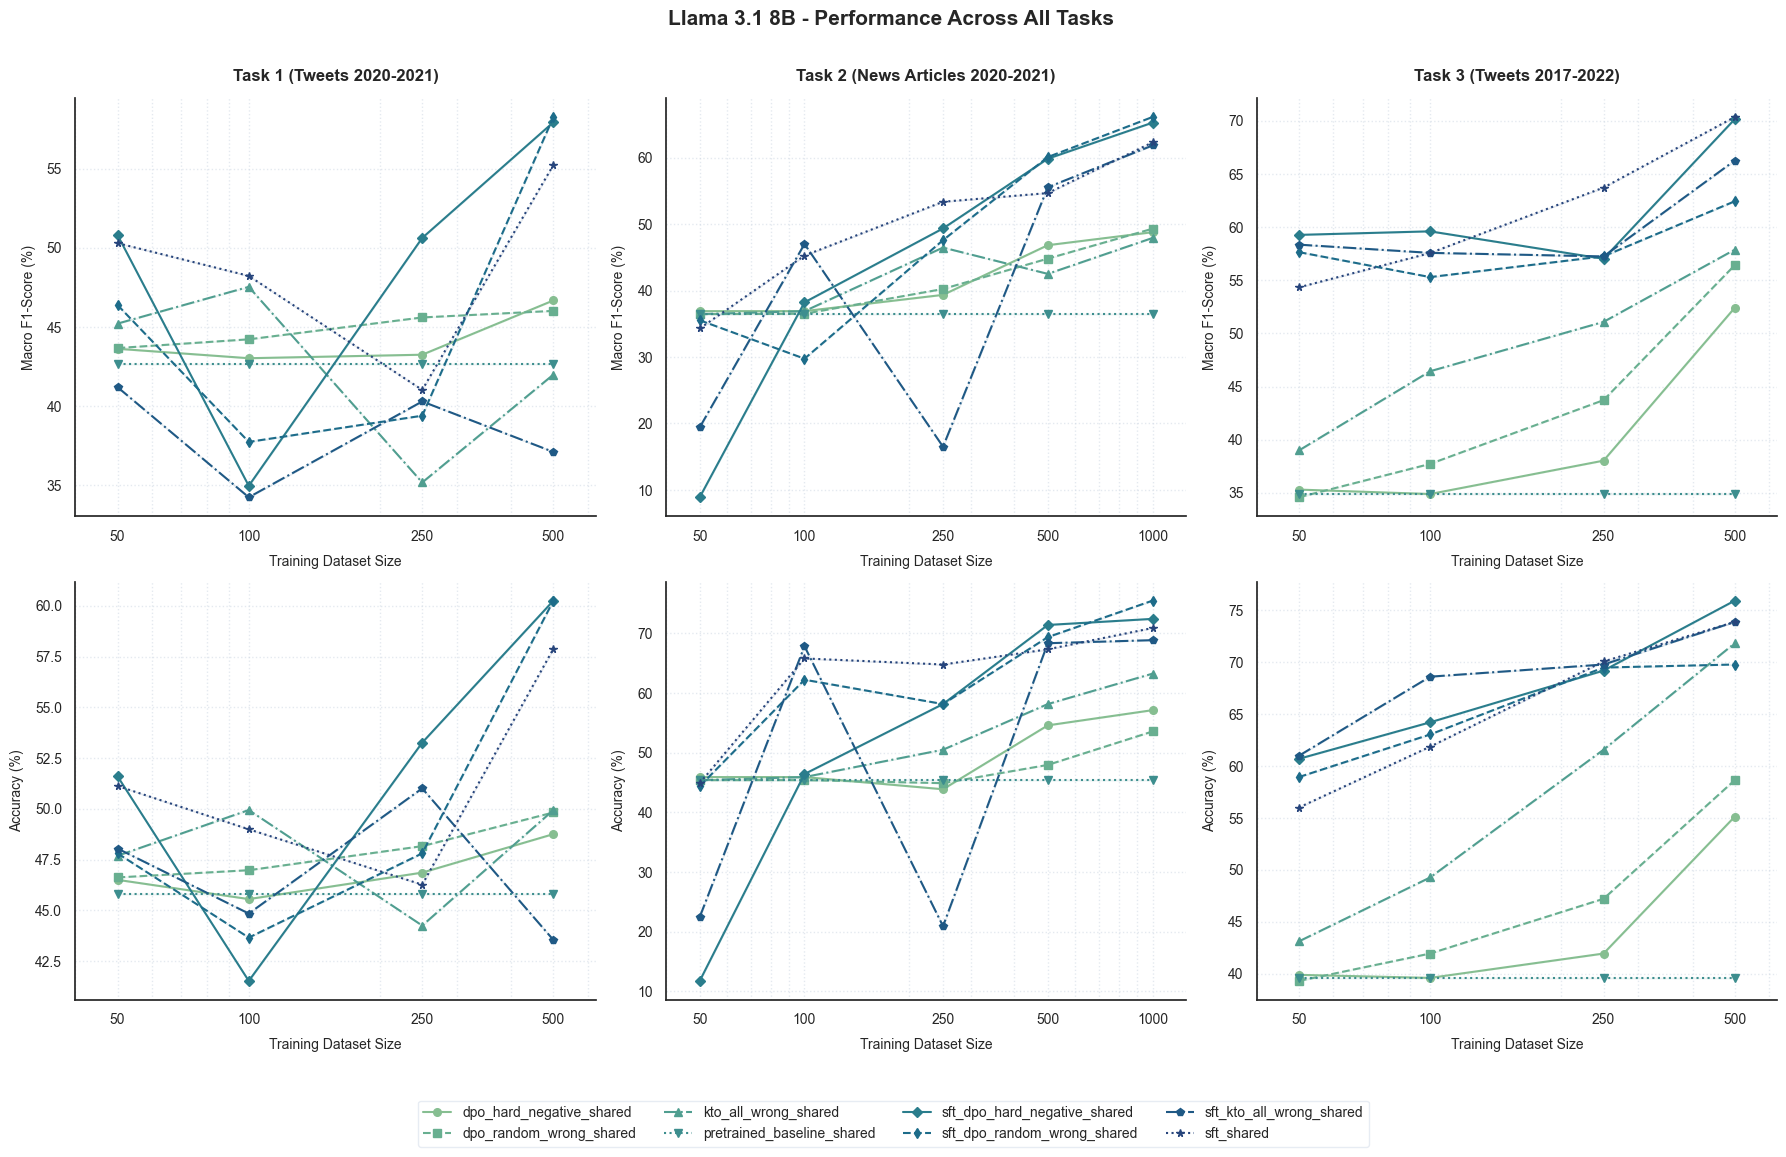

task comparison for Llama 3.1 8B saved successfully at:
/Users/ematheve/Desktop/DPO-main/Results_data_figures/merged_tasks_llama31_shared.png


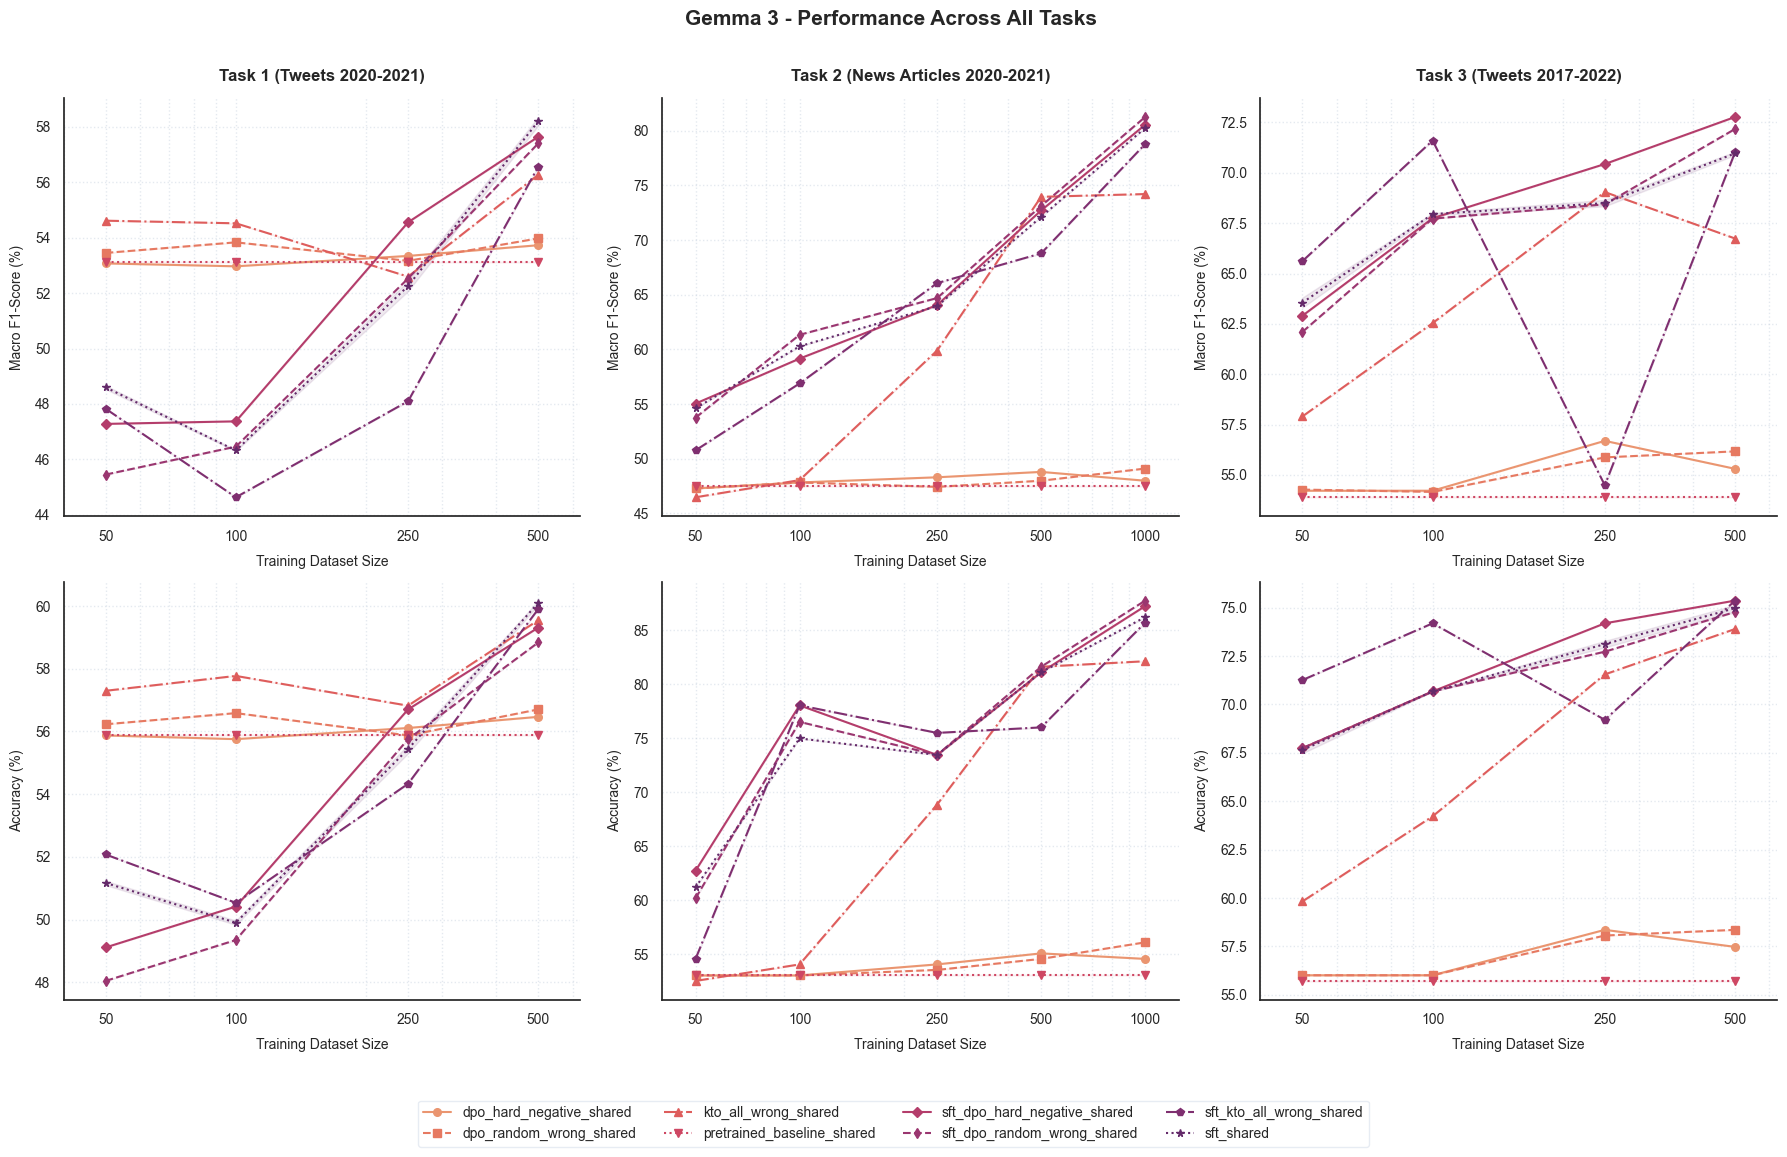

task comparison for Gemma 3 saved successfully at:
/Users/ematheve/Desktop/DPO-main/Results_data_figures/merged_tasks_gemma3_shared.png


In [ ]:
def plot_merged_tasks_by_model(workspace_dir, model_id, palette_name):
    import matplotlib.pyplot as plt
    import matplotlib.ticker as ticker
    import seaborn as sns
    import os
    
    tasks = [
        {
            'internal_id': 'ds1_task6',
            'friendly_name': 'Task 1 (Tweets 2020-2021)'
        },
        {
            'internal_id': 'ds4_task2',
            'friendly_name': 'Task 2 (News Articles 2020-2021)'
        },
        {
            'internal_id': 'ds3_task6',
            'friendly_name': 'Task 3 (Tweets 2017-2022)'
        }
    ]
    
    model_friendly = "Llama 3.1 8B" if model_id == "llama31" else "Gemma 3"
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 11))
    
    baselines = ['pretrained_baseline']
    linestyles = ['-', '--', '-.', ':']
    markers = ['o', 's', '^', 'v', 'D', 'd', 'p', '*', 'h', 'P', 'X']
    
    legend_info = {}
    
    all_keys = set()
    configs_by_task = {}
    for t in tasks:
        configs = load_all_task_configs(workspace_dir, model_id, t['internal_id'])
        if model_id == "llama31":
            shared_configs = {k: v for k, v in configs.items() if 'shared' in k or k == 'pretrained_baseline'}
        else:
            shared_configs = {k: v for k, v in configs.items() if 'shared' in k or k == 'pretrained_baseline' or k == 'sft'}
        configs_by_task[t['internal_id']] = shared_configs
        for k in shared_configs.keys():
            if k not in baselines:
                all_keys.add(k)
                
    sorted_keys = sorted(list(all_keys))
    if not sorted_keys:
        print(f"No shared configuration data found for {model_friendly}")
        return
        
    palette = sns.color_palette(palette_name, n_colors=max(len(sorted_keys), 1))
    color_map = {k: palette[i] for i, k in enumerate(sorted_keys)}
    style_map = {k: linestyles[i % len(linestyles)] for i, k in enumerate(sorted_keys)}
    marker_map = {k: markers[i % len(markers)] for i, k in enumerate(sorted_keys)}
    
    for idx, t in enumerate(tasks):
        configs = configs_by_task[t['internal_id']]
        ax_f1 = axes[0, idx]
        ax_acc = axes[1, idx]
        
        for config_name in baselines:
            if config_name in configs:
                data = configs[config_name]
                lbl = f"{model_friendly} Baseline: {config_name}"
                l_f1, = ax_f1.plot(data['train_sizes'], data['macro_f1'], color='#64748B', linestyle='--', linewidth=1.2, alpha=0.8)
                l_acc, = ax_acc.plot(data['train_sizes'], data['accuracy'], color='#64748B', linestyle='--', linewidth=1.2, alpha=0.8)
                if lbl not in legend_info:
                    legend_info[lbl] = l_f1
                    
        for config_name in sorted_keys:
            if config_name in configs:
                data = configs[config_name]
                color = color_map[config_name]
                linestyle = style_map[config_name]
                marker = marker_map[config_name]
                
                lbl = f"{config_name}"
                l_f1, = ax_f1.plot(data['train_sizes'], data['macro_f1'], color=color,
 linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
                ax_f1.fill_between(data['train_sizes'], data['macro_f1'] - data['macro_f1_std'], data['macro_f1'] + data['macro_f1_std'],
                                 color=color, alpha=0.10)
                                 
                l_acc, = ax_acc.plot(data['train_sizes'], data['accuracy'], color=color,
                                linestyle=linestyle, marker=marker, markersize=5.5, linewidth=1.5)
                ax_acc.fill_between(data['train_sizes'], data['accuracy'] - data['accuracy_std'], data['accuracy'] + data['accuracy_std'],
                                 color=color, alpha=0.10)
                
                if lbl not in legend_info:
                    legend_info[lbl] = l_f1
                    
        for row_idx, (ax, metric_name) in enumerate([(ax_f1, "Macro F1-Score (%)"), (ax_acc, "Accuracy (%)")]):
            if row_idx == 0:
                ax.set_title(f"{t['friendly_name']}", fontsize=12, fontweight='bold', pad=12)
            ax.set_xlabel("Training Dataset Size", fontsize=10, labelpad=8)
            ax.set_ylabel(metric_name, fontsize=10, labelpad=8)
            ax.set_xscale('log')
            
            all_x = []
            for d in list(configs.values()):
                all_x.extend(list(d['train_sizes']))
            if all_x:
                unique_x = sorted(list(set(all_x)))
                ax.set_xticks(unique_x)
                ax.get_xaxis().set_major_formatter(ticker.ScalarFormatter())
                ax.set_xlim(min(unique_x) * 0.8, max(unique_x) * 1.25)
            ax.grid(True, which='both', linestyle=':', alpha=0.5, color='#CBD5E1')
            sns.despine(ax=ax, top=True, right=True)
            
    handles = list(legend_info.values())
    labels = list(legend_info.keys())
    fig.legend(handles, labels, loc='lower center', bbox_to_anchor=(0.5, -0.06),
               ncol=min(len(labels), 4), frameon=True, facecolor='white', edgecolor='#E2E8F0', fontsize=10)
               
    plt.suptitle(f"{model_friendly} - Performance Across All Tasks ", fontsize=15, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.subplots_adjust(top=0.90, bottom=0.08)
    
    merged_fig_path = os.path.join(workspace_dir, 'Results_data_figures', f'merged_tasks_{model_id}_shared.png')
    fig.savefig(merged_fig_path, dpi=300, bbox_inches='tight')
    plt.show()
    print(f"task comparison for {model_friendly} saved successfully at:\n{merged_fig_path}")

plot_merged_tasks_by_model(WORKSPACE_DIR, 'llama31', 'crest')
plot_merged_tasks_by_model(WORKSPACE_DIR, 'gemma3', 'flare')